# Molecular Data Machine Learning
### Notebook by Debisree Ray

https://www.kaggle.com/competitions/molecular-machine-learning

In [1]:
!pip install rdkit-pypi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.4/29.4 MB 52.0 MB/s eta 0:00:00


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/molecular-machine-learning/sample_submission.csv
/kaggle/input/molecular-machine-learning/train.csv
/kaggle/input/molecular-machine-learning/test.csv


In [3]:
#import libraries:

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import shap
import re
from scipy.stats import linregress

from sklearn.model_selection import cross_val_score

from sklearn.model_selection import train_test_split,  KFold
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from xgboost import XGBRegressor


from sklearn.model_selection import RandomizedSearchCV
import optuna

from imblearn.over_sampling import SMOTE

from sklearn.metrics import mean_squared_error

from sklearn.metrics import mean_squared_log_error

# Import regressors
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor



import warnings
warnings.simplefilter("ignore")
pd.options.mode.chained_assignment = None  

pd.set_option('display.max_columns', None)

In [4]:
train = pd.read_csv('/kaggle/input/molecular-machine-learning/train.csv')
test = pd.read_csv('/kaggle/input/molecular-machine-learning/test.csv')

In [5]:
train.head()

,Batch_ID,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,RingCount,NumRotatableBonds,NumHeteroatoms,HOMOm1(eV),HOMO(eV),LUMO(eV),LUMOp1(eV),PrimeState,PrimeExcite(eV),PrimeExcite(osc),DipoleMoment(Debye),SurfaceCharge,ChargeCorrection,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T20,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20,O1,O2,O3,O4,O5,O6,O7,O8,O9,O10,O11,O12,O13,O14,O15,O16,O17,O18,O19,O20,TDOS1.5,TDOS1.6,TDOS1.7,TDOS1.8,TDOS1.9,TDOS2.0,TDOS2.1,TDOS2.2,TDOS2.3,TDOS2.4,TDOS2.5,TDOS2.6,TDOS2.7,TDOS2.8,TDOS2.9,TDOS3.0,TDOS3.1,TDOS3.2,TDOS3.3,TDOS3.4,TDOS3.5,TDOS3.6,TDOS3.7,TDOS3.8,TDOS3.9,TDOS4.0,TDOS4.1,TDOS4.2,TDOS4.3,TDOS4.4,TDOS4.5,TDOS4.6,TDOS4.7,SDOS2.5,SDOS2.6,SDOS2.7,SDOS2.8,SDOS2.9,SDOS3.0,SDOS3.1,SDOS3.2,SDOS3.3,SDOS3.4,SDOS3.5,SDOS3.6,SDOS3.7,SDOS3.8,SDOS3.9,SDOS4.0,SDOS4.1,SDOS4.2,SDOS4.3,SDOS4.4,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4
0,Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,3,13,2,-8.8374,-7.8893,0.3472,1.4773,1,4.604816,0.987886,0.57258,-0.038114,0.00245,3.135243,3.673961,4.292212,4.432521,4.475070,4.486092,4.755836,4.813945,5.640073,5.913449,6.030660,6.114731,6.245629,6.267871,6.451262,6.490043,6.554413,6.597794,6.778545,6.957696,4.604816,5.008457,5.535707,5.777369,5.806281,6.180701,6.321331,6.460635,6.465954,6.654304,6.656871,6.819904,6.920167,6.951335,7.059793,7.263257,7.330665,7.407061,7.430419,7.571409,0.987886,0.000843,0.015068,0.017847,0.104293,0.056222,0.072319,0.059375,0.051553,0.021097,0.022424,0.028070,0.003625,0.038192,0.010176,0.602064,0.016987,0.065429,0.015649,0.118870,6.070000e-15,3.200000e-13,1.310000e-11,4.180000e-10,1.040000e-08,2.010000e-07,3.030000e-06,3.560000e-05,3.255820e-04,0.002319,0.012859,0.055546,0.186862,0.489651,0.999874,1.593854,1.996452,2.013180,1.768059,1.611227,1.745397,2.002522,2.044195,1.765658,1.463189,1.631723,2.629855,4.422731,6.485324,8.017557,8.478704,7.950547,6.865207,1.750000e-24,2.990000e-22,3.960000e-20,4.090000e-18,3.290000e-16,2.060000e-14,1.000000e-12,3.810000e-11,1.130000e-09,2.600000e-08,4.660000e-07,6.510000e-06,7.080000e-05,6.001750e-04,3.961032e-03,2.035942e-02,0.081498,0.254073,0.616874,1.166442,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340
1,Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,2,12,2,-9.0870,-8.2034,0.8586,1.8912,1,5.074787,0.386292,1.68691,-0.039476,0.00243,3.385683,3.898514,4.438670,4.616185,5.703688,5.850009,6.111718,6.188610,6.315764,6.339197,6.467256,6.607167,6.695862,6.890114,7.120618,7.124449,7.201143,7.294277,7.600110,7.752693,5.074787,5.814575,5.920305,6.014307,6.291501,6.587479,6.659053,6.802349,6.891912,7.142401,7.317014,7.322656,7.652938,7.782386,7.858026,8.006802,8.008972,8.124261,8.245476,8.323199,0.386292,0.075833,0.018200,0.090356,0.013351,0.007066,0.034101,0.001254,0.032699,0.042854,0.009285,0.013903,0.003854,0.003978,0.175448,0.046715,0.256225,0.023161,0.121842,0.007268,9.920000e-20,9.760000e-18,7.480000e-16,4.470000e-14,2.080000e-12,7.520000e-11,2.120000e-09,4.660000e-08,7.960000e-07,0.000011,0.000110,0.000889,0.005591,0.027398,0.104557,0.310793,0.719839,1.300789,1.842464,2.078892,1.968111,1.778528,1.801242,2.012835,2.124073,1.968890,1.751188,1.848447,2.406233,3.155962,3.609764,3.433183,2.677125,7.890000e-37,4.350000e-34,1.870000e-31,6.240000e-29,1.620000e-26,3.290000e-24,5.200000e-22,6.400000e-20,6.130000e-18,4.570000e-16,2.650000e-14,1.200000e-12,4.230000e-11,1.160000e-09,2.480000e-08,4.130000e-07,0.000005,0.000054,0.000425,0.002600,0.012396,0.046031,0.133124,0.299840,0.525958,0.718549,0.764711,0.634854,0.414866,0.225909
2,Train-03,78.30,CN1CCN(S(=O)(=O)c2ccc(-c3ccc(-c4cccs4)cc3)cc2)CC1,398.553,4,0,4.0182,0.799589,5.368024,40.62,4,4,6,-8.2055,-8.0072,0.0730,1.2317,1,4.591711,1.277359,8.93223,-0.032458,-0.00467,3.175326,3.780857,4.331316,4.494994,4.526621,4.553525,4.610283,4.707483,4.7

In [6]:
test.head()

,Batch_ID,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,RingCount,NumRotatableBonds,NumHeteroatoms,HOMOm1(eV),HOMO(eV),LUMO(eV),LUMOp1(eV),PrimeState,PrimeExcite(eV),PrimeExcite(osc),DipoleMoment(Debye),SurfaceCharge,ChargeCorrection,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T20,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20,O1,O2,O3,O4,O5,O6,O7,O8,O9,O10,O11,O12,O13,O14,O15,O16,O17,O18,O19,O20,TDOS1.5,TDOS1.6,TDOS1.7,TDOS1.8,TDOS1.9,TDOS2.0,TDOS2.1,TDOS2.2,TDOS2.3,TDOS2.4,TDOS2.5,TDOS2.6,TDOS2.7,TDOS2.8,TDOS2.9,TDOS3.0,TDOS3.1,TDOS3.2,TDOS3.3,TDOS3.4,TDOS3.5,TDOS3.6,TDOS3.7,TDOS3.8,TDOS3.9,TDOS4.0,TDOS4.1,TDOS4.2,TDOS4.3,TDOS4.4,TDOS4.5,TDOS4.6,TDOS4.7,SDOS2.5,SDOS2.6,SDOS2.7,SDOS2.8,SDOS2.9,SDOS3.0,SDOS3.1,SDOS3.2,SDOS3.3,SDOS3.4,SDOS3.5,SDOS3.6,SDOS3.7,SDOS3.8,SDOS3.9,SDOS4.0,SDOS4.1,SDOS4.2,SDOS4.3,SDOS4.4,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4
0,Test-01,NaN,COC(=O)c3ccc(c2ccc(c1ccco1)cc2)s3,284.336,4,0,4.4617,0.796737,4.323524,39.44,3,4,4,-9.1767,-7.8628,-0.2558,0.9907,1,4.158140,1.533749,2.99293,-0.023229,-0.00074,2.859165,3.439515,4.106838,4.370295,4.454874,4.748484,4.774792,5.075952,5.262467,5.558953,5.781386,6.009521,6.108147,6.243360,6.330382,6.507983,6.609064,6.722580,7.064281,7.131156,4.158140,4.954848,5.220686,5.431601,5.472229,6.034107,6.226065,6.498548,6.624090,6.719344,6.911811,6.969263,7.041766,7.162969,7.229844,7.271216,7.358002,7.361325,7.406788,7.630052,1.533749,0.000125,0.003866,0.106472,0.002534,0.035107,0.199289,0.308479,0.013632,0.031688,0.003006,0.151648,0.172323,0.200949,0.088386,0.008776,0.239277,0.069055,0.101257,0.017023,1.870000e-10,4.930000e-09,1.010000e-07,1.620000e-06,2.020000e-05,1.961660e-04,1.483072e-03,0.008732,0.040043,0.143004,0.397758,0.861798,1.455435,1.921326,2.006011,1.735020,1.438261,1.440739,1.740251,2.011562,1.937473,1.529568,1.115270,1.051548,1.477906,2.281232,3.232804,4.143487,4.886269,5.363662,5.580913,5.661393,5.654575,3.630000e-15,2.020000e-13,8.780000e-12,2.970000e-10,7.810000e-09,1.600000e-07,2.550000e-06,3.180000e-05,3.075580e-04,2.319284e-03,0.013621,0.062300,0.221919,0.615640,1.330106,2.238061,2.932809,2.993107,2.378960,1.472584,0.709932,0.266678,0.078569,0.020244,0.011813,0.025880,0.061288,0.118430,0.181805,0.220200
1,Test-02,NaN,CCCCCCc2c(CCCCCC)c(c1cccs1)sc2c3ccc(C(=O)OC)cc3,468.728,4,0,9.1758,0.268870,5.019005,26.30,3,16,4,-8.5808,-7.4499,-0.4427,0.7455,1,4.530527,0.970237,2.95569,-0.036913,-0.00292,3.193787,3.705192,3.924227,4.234215,4.453796,4.596323,4.726737,5.034419,5.057181,5.371062,5.689529,5.769372,5.809182,5.900531,5.995041,6.228049,6.312392,6.442249,6.536486,6.580685,4.530527,5.154692,5.288875,5.425489,5.459769,5.904436,5.950432,5.988457,6.108110,6.224168,6.282959,6.624475,6.642749,6.722667,6.912021,7.003953,7.064380,7.119998,7.169429,7.259463,0.970237,0.012245,0.098765,0.121424,0.005682,0.062623,0.100178,0.148465,0.088108,0.033143,0.046049,0.015795,0.009955,0.051240,0.083519,0.056209,0.030987,0.738391,0.133419,0.405883,5.310000e-16,3.240000e-14,1.540000e-12,5.670000e-11,1.630000e-09,3.660000e-08,6.390000e-07,0.000009,0.000092,0.000757,0.004862,0.024312,0.094680,0.287192,0.678759,1.251456,1.807922,2.078694,2.003900,1.859530,2.008968,2.539952,3.197128,3.646909,3.767226,3.713203,3.756261,4.064592,4.613465,5.240489,5.722240,5.870502,5.694369,8.020000e-23,1.130000e-20,1.250000e-18,1.070000e-16,7.140000e-15,3.720000e-13,1.500000e-11,4.750000e-10,1.170000e-08,2.230000e-07,0.000003,0.000039,0.000348,0.002453,0.013443,0.057386,0.190781,0.493954,0.996014,1.564144,1.913133,1.823127,1.356344,0.797689,0.399819,0.236639,0.250003,0.343148,0.426963,0.445557
2,Test-03,NaN,COC(=O)c3ccc(c2ccc(c1cccc(OC)c1)cc2)s3,324.401,4,0,4.8773,0.846029,4.976660,35.53,3,6,4,-8.6000,-8.2543,-0.2233,0.9632,1,4.367121,1.438631,4.37442,-0.026539,-0.00236,2.986467,3.796416,4.099808,4.197169,4.258329,4.527489,4.637893,4.781623,4.855850,5.076621,5.406086,5.561334,5.813633,6.177961,6.274628,6.364

'T80' is the Target - that needs to be calculated. Dropping the column from test dataset.

In [7]:
test.drop('T80', axis=1, inplace=True)

In [8]:
train.shape

(42, 146)

In [9]:
test.shape

(9, 145)

In [10]:
print(list(train.columns))

['Batch_ID', 'T80', 'Smiles', 'Mass', 'HAcceptors', 'HDonors', 'LogP', 'Asphericity', 'Rg', 'TPSA', 'RingCount', 'NumRotatableBonds', 'NumHeteroatoms', 'HOMOm1(eV)', 'HOMO(eV)', 'LUMO(eV)', 'LUMOp1(eV)', 'PrimeState', 'PrimeExcite(eV)', 'PrimeExcite(osc)', 'DipoleMoment(Debye)', 'SurfaceCharge', 'ChargeCorrection', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'T16', 'T17', 'T18', 'T19', 'T20', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8', 'O9', 'O10', 'O11', 'O12', 'O13', 'O14', 'O15', 'O16', 'O17', 'O18', 'O19', 'O20', 'TDOS1.5', 'TDOS1.6', 'TDOS1.7', 'TDOS1.8', 'TDOS1.9', 'TDOS2.0', 'TDOS2.1', 'TDOS2.2', 'TDOS2.3', 'TDOS2.4', 'TDOS2.5', 'TDOS2.6', 'TDOS2.7', 'TDOS2.8', 'TDOS2.9', 'TDOS3.0', 'TDOS3.1', 'TDOS3.2', 'TDOS3.3', 'TDOS3.4', 'TDOS3.5', 'TDOS3.6', 'TDOS3.7', 'TDOS3.8', 'TDOS3.9', 'TDOS4.0', 'TDO

# Missing Value

In [11]:
train.columns[train.isnull().any()]

Index([], dtype='object')

No missing value in train data

In [12]:
test.columns[test.isnull().any()]

Index([], dtype='object')

No missing value in test data as well

In [13]:
train.head()

,Batch_ID,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,RingCount,NumRotatableBonds,NumHeteroatoms,HOMOm1(eV),HOMO(eV),LUMO(eV),LUMOp1(eV),PrimeState,PrimeExcite(eV),PrimeExcite(osc),DipoleMoment(Debye),SurfaceCharge,ChargeCorrection,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T20,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20,O1,O2,O3,O4,O5,O6,O7,O8,O9,O10,O11,O12,O13,O14,O15,O16,O17,O18,O19,O20,TDOS1.5,TDOS1.6,TDOS1.7,TDOS1.8,TDOS1.9,TDOS2.0,TDOS2.1,TDOS2.2,TDOS2.3,TDOS2.4,TDOS2.5,TDOS2.6,TDOS2.7,TDOS2.8,TDOS2.9,TDOS3.0,TDOS3.1,TDOS3.2,TDOS3.3,TDOS3.4,TDOS3.5,TDOS3.6,TDOS3.7,TDOS3.8,TDOS3.9,TDOS4.0,TDOS4.1,TDOS4.2,TDOS4.3,TDOS4.4,TDOS4.5,TDOS4.6,TDOS4.7,SDOS2.5,SDOS2.6,SDOS2.7,SDOS2.8,SDOS2.9,SDOS3.0,SDOS3.1,SDOS3.2,SDOS3.3,SDOS3.4,SDOS3.5,SDOS3.6,SDOS3.7,SDOS3.8,SDOS3.9,SDOS4.0,SDOS4.1,SDOS4.2,SDOS4.3,SDOS4.4,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4
0,Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,3,13,2,-8.8374,-7.8893,0.3472,1.4773,1,4.604816,0.987886,0.57258,-0.038114,0.00245,3.135243,3.673961,4.292212,4.432521,4.475070,4.486092,4.755836,4.813945,5.640073,5.913449,6.030660,6.114731,6.245629,6.267871,6.451262,6.490043,6.554413,6.597794,6.778545,6.957696,4.604816,5.008457,5.535707,5.777369,5.806281,6.180701,6.321331,6.460635,6.465954,6.654304,6.656871,6.819904,6.920167,6.951335,7.059793,7.263257,7.330665,7.407061,7.430419,7.571409,0.987886,0.000843,0.015068,0.017847,0.104293,0.056222,0.072319,0.059375,0.051553,0.021097,0.022424,0.028070,0.003625,0.038192,0.010176,0.602064,0.016987,0.065429,0.015649,0.118870,6.070000e-15,3.200000e-13,1.310000e-11,4.180000e-10,1.040000e-08,2.010000e-07,3.030000e-06,3.560000e-05,3.255820e-04,0.002319,0.012859,0.055546,0.186862,0.489651,0.999874,1.593854,1.996452,2.013180,1.768059,1.611227,1.745397,2.002522,2.044195,1.765658,1.463189,1.631723,2.629855,4.422731,6.485324,8.017557,8.478704,7.950547,6.865207,1.750000e-24,2.990000e-22,3.960000e-20,4.090000e-18,3.290000e-16,2.060000e-14,1.000000e-12,3.810000e-11,1.130000e-09,2.600000e-08,4.660000e-07,6.510000e-06,7.080000e-05,6.001750e-04,3.961032e-03,2.035942e-02,0.081498,0.254073,0.616874,1.166442,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340
1,Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,2,12,2,-9.0870,-8.2034,0.8586,1.8912,1,5.074787,0.386292,1.68691,-0.039476,0.00243,3.385683,3.898514,4.438670,4.616185,5.703688,5.850009,6.111718,6.188610,6.315764,6.339197,6.467256,6.607167,6.695862,6.890114,7.120618,7.124449,7.201143,7.294277,7.600110,7.752693,5.074787,5.814575,5.920305,6.014307,6.291501,6.587479,6.659053,6.802349,6.891912,7.142401,7.317014,7.322656,7.652938,7.782386,7.858026,8.006802,8.008972,8.124261,8.245476,8.323199,0.386292,0.075833,0.018200,0.090356,0.013351,0.007066,0.034101,0.001254,0.032699,0.042854,0.009285,0.013903,0.003854,0.003978,0.175448,0.046715,0.256225,0.023161,0.121842,0.007268,9.920000e-20,9.760000e-18,7.480000e-16,4.470000e-14,2.080000e-12,7.520000e-11,2.120000e-09,4.660000e-08,7.960000e-07,0.000011,0.000110,0.000889,0.005591,0.027398,0.104557,0.310793,0.719839,1.300789,1.842464,2.078892,1.968111,1.778528,1.801242,2.012835,2.124073,1.968890,1.751188,1.848447,2.406233,3.155962,3.609764,3.433183,2.677125,7.890000e-37,4.350000e-34,1.870000e-31,6.240000e-29,1.620000e-26,3.290000e-24,5.200000e-22,6.400000e-20,6.130000e-18,4.570000e-16,2.650000e-14,1.200000e-12,4.230000e-11,1.160000e-09,2.480000e-08,4.130000e-07,0.000005,0.000054,0.000425,0.002600,0.012396,0.046031,0.133124,0.299840,0.525958,0.718549,0.764711,0.634854,0.414866,0.225909
2,Train-03,78.30,CN1CCN(S(=O)(=O)c2ccc(-c3ccc(-c4cccs4)cc3)cc2)CC1,398.553,4,0,4.0182,0.799589,5.368024,40.62,4,4,6,-8.2055,-8.0072,0.0730,1.2317,1,4.591711,1.277359,8.93223,-0.032458,-0.00467,3.175326,3.780857,4.331316,4.494994,4.526621,4.553525,4.610283,4.707483,4.7

In [14]:
#Set index
train.set_index('Batch_ID', inplace=True)
test.set_index('Batch_ID', inplace=True)

In [15]:
# Convert a SMILES string into an RDKit molecule

train['mol'] = train['Smiles'].apply(lambda s: Chem.MolFromSmiles(s))
test['mol'] = test['Smiles'].apply(lambda s: Chem.MolFromSmiles(s))
train.head()

,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,RingCount,NumRotatableBonds,NumHeteroatoms,HOMOm1(eV),HOMO(eV),LUMO(eV),LUMOp1(eV),PrimeState,PrimeExcite(eV),PrimeExcite(osc),DipoleMoment(Debye),SurfaceCharge,ChargeCorrection,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T20,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20,O1,O2,O3,O4,O5,O6,O7,O8,O9,O10,O11,O12,O13,O14,O15,O16,O17,O18,O19,O20,TDOS1.5,TDOS1.6,TDOS1.7,TDOS1.8,TDOS1.9,TDOS2.0,TDOS2.1,TDOS2.2,TDOS2.3,TDOS2.4,TDOS2.5,TDOS2.6,TDOS2.7,TDOS2.8,TDOS2.9,TDOS3.0,TDOS3.1,TDOS3.2,TDOS3.3,TDOS3.4,TDOS3.5,TDOS3.6,TDOS3.7,TDOS3.8,TDOS3.9,TDOS4.0,TDOS4.1,TDOS4.2,TDOS4.3,TDOS4.4,TDOS4.5,TDOS4.6,TDOS4.7,SDOS2.5,SDOS2.6,SDOS2.7,SDOS2.8,SDOS2.9,SDOS3.0,SDOS3.1,SDOS3.2,SDOS3.3,SDOS3.4,SDOS3.5,SDOS3.6,SDOS3.7,SDOS3.8,SDOS3.9,SDOS4.0,SDOS4.1,SDOS4.2,SDOS4.3,SDOS4.4,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4,mol
Batch_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,3,13,2,-8.8374,-7.8893,0.3472,1.4773,1,4.604816,0.987886,0.57258,-0.038114,0.00245,3.135243,3.673961,4.292212,4.432521,4.475070,4.486092,4.755836,4.813945,5.640073,5.913449,6.030660,6.114731,6.245629,6.267871,6.451262,6.490043,6.554413,6.597794,6.778545,6.957696,4.604816,5.008457,5.535707,5.777369,5.806281,6.180701,6.321331,6.460635,6.465954,6.654304,6.656871,6.819904,6.920167,6.951335,7.059793,7.263257,7.330665,7.407061,7.430419,7.571409,0.987886,0.000843,0.015068,0.017847,0.104293,0.056222,0.072319,0.059375,0.051553,0.021097,0.022424,0.028070,0.003625,0.038192,0.010176,0.602064,0.016987,0.065429,0.015649,0.118870,6.070000e-15,3.200000e-13,1.310000e-11,4.180000e-10,1.040000e-08,2.010000e-07,3.030000e-06,3.560000e-05,3.255820e-04,0.002319,0.012859,0.055546,0.186862,0.489651,0.999874,1.593854,1.996452,2.013180,1.768059,1.611227,1.745397,2.002522,2.044195,1.765658,1.463189,1.631723,2.629855,4.422731,6.485324,8.017557,8.478704,7.950547,6.865207,1.750000e-24,2.990000e-22,3.960000e-20,4.090000e-18,3.290000e-16,2.060000e-14,1.000000e-12,3.810000e-11,1.130000e-09,2.600000e-08,4.660000e-07,6.510000e-06,7.080000e-05,6.001750e-04,3.961032e-03,2.035942e-02,0.081498,0.254073,0.616874,1.166442,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340,<rdkit.Chem.rdchem.Mol object at 0x7aa1f2a22a40>
Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,2,12,2,-9.0870,-8.2034,0.8586,1.8912,1,5.074787,0.386292,1.68691,-0.039476,0.00243,3.385683,3.898514,4.438670,4.616185,5.703688,5.850009,6.111718,6.188610,6.315764,6.339197,6.467256,6.607167,6.695862,6.890114,7.120618,7.124449,7.201143,7.294277,7.600110,7.752693,5.074787,5.814575,5.920305,6.014307,6.291501,6.587479,6.659053,6.802349,6.891912,7.142401,7.317014,7.322656,7.652938,7.782386,7.858026,8.006802,8.008972,8.124261,8.245476,8.323199,0.386292,0.075833,0.018200,0.090356,0.013351,0.007066,0.034101,0.001254,0.032699,0.042854,0.009285,0.013903,0.003854,0.003978,0.175448,0.046715,0.256225,0.023161,0.121842,0.007268,9.920000e-20,9.760000e-18,7.480000e-16,4.470000e-14,2.080000e-12,7.520000e-11,2.120000e-09,4.660000e-08,7.960000e-07,0.000011,0.000110,0.000889,0.005591,0.027398,0.104557,0.310793,0.719839,1.300789,1.842464,2.078892,1.968111,1.778528,1.801242,2.012835,2.124073,1.968890,1.751188,1.848447,2.406233,3.155962,3.609764,3.433183,2.677125,7.890000e-37,4.350000e-34,1.870000e-31,6.240000e-29,1.620000e-26,3.290000e-24,5.200000e-22,6.400000e-20,6.130000e-18,4.570000e-16,2.650000e-14,1.200000e-12,4.230000e-11,1.160000e-09,2.480000e-08,4.130000e-07,0.000005,0.000054,0.000425,0.002600,0.012396,0.046031,0.133124,0.299840,0.525958,0.718549,0.764711,0.634854,0.414866,0.225909,<rdkit.Chem.rdchem.Mol object at 0x7aa1f2a22810>
Train-03,78.30,CN1CCN(S(


# Feature creation

### Fraction of sp³ Carbons (Fsp³):
Measures the proportion of sp³-hybridized carbons, which has been linked to molecule complexity and three-dimensionality.


### BertzCT (Molecular Complexity):
A complexity index based on the count and connectivity of atoms within the molecule.


### Chi Indices:
These are connectivity indices (e.g., Chi0, Chi1, Chi2) that capture information about branching and the overall topology of the molecule.



In [16]:
train['Fsp3'] = train['mol'].apply(lambda m: rdMolDescriptors.CalcFractionCSP3(m))
train['BertzCT'] = train['mol'].apply(lambda m: Descriptors.BertzCT(m))
train['Chi0'] = train['mol'].apply(lambda m: Descriptors.Chi0(m))
train['Chi1'] = train['mol'].apply(lambda m: Descriptors.Chi1(m))
train['NumAromaticRings'] = train['mol'].apply(lambda m: Descriptors.NumAromaticRings(m))
train['NumAliphaticRings'] = train['mol'].apply(lambda m: Descriptors.NumAliphaticRings(m))
train['FractionCSP3'] = train['mol'].apply(lambda m: Descriptors.FractionCSP3(m)) 
train['HeavyAtomCount'] = train['mol'].apply(lambda m: Descriptors.HeavyAtomCount(m)) 
            
           


test['Fsp3'] = test['mol'].apply(lambda m: rdMolDescriptors.CalcFractionCSP3(m))
test['BertzCT'] = test['mol'].apply(lambda m: Descriptors.BertzCT(m))
test['Chi0'] = test['mol'].apply(lambda m: Descriptors.Chi0(m))
test['Chi1'] = test['mol'].apply(lambda m: Descriptors.Chi1(m))
test['NumAromaticRings'] = test['mol'].apply(lambda m: Descriptors.NumAromaticRings(m))
test['NumAliphaticRings'] = test['mol'].apply(lambda m: Descriptors.NumAliphaticRings(m))
test['FractionCSP3'] = test['mol'].apply(lambda m: Descriptors.FractionCSP3(m)) 
test['HeavyAtomCount'] = test['mol'].apply(lambda m: Descriptors.HeavyAtomCount(m)) 


train.head()

,T80,Smiles,Mass,HAcceptors,HDonors,LogP,Asphericity,Rg,TPSA,RingCount,NumRotatableBonds,NumHeteroatoms,HOMOm1(eV),HOMO(eV),LUMO(eV),LUMOp1(eV),PrimeState,PrimeExcite(eV),PrimeExcite(osc),DipoleMoment(Debye),SurfaceCharge,ChargeCorrection,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T20,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20,O1,O2,O3,O4,O5,O6,O7,O8,O9,O10,O11,O12,O13,O14,O15,O16,O17,O18,O19,O20,TDOS1.5,TDOS1.6,TDOS1.7,TDOS1.8,TDOS1.9,TDOS2.0,TDOS2.1,TDOS2.2,TDOS2.3,TDOS2.4,TDOS2.5,TDOS2.6,TDOS2.7,TDOS2.8,TDOS2.9,TDOS3.0,TDOS3.1,TDOS3.2,TDOS3.3,TDOS3.4,TDOS3.5,TDOS3.6,TDOS3.7,TDOS3.8,TDOS3.9,TDOS4.0,TDOS4.1,TDOS4.2,TDOS4.3,TDOS4.4,TDOS4.5,TDOS4.6,TDOS4.7,SDOS2.5,SDOS2.6,SDOS2.7,SDOS2.8,SDOS2.9,SDOS3.0,SDOS3.1,SDOS3.2,SDOS3.3,SDOS3.4,SDOS3.5,SDOS3.6,SDOS3.7,SDOS3.8,SDOS3.9,SDOS4.0,SDOS4.1,SDOS4.2,SDOS4.3,SDOS4.4,SDOS4.5,SDOS4.6,SDOS4.7,SDOS4.8,SDOS4.9,SDOS5.0,SDOS5.1,SDOS5.2,SDOS5.3,SDOS5.4,mol,Fsp3,BertzCT,Chi0,Chi1,NumAromaticRings,NumAliphaticRings,FractionCSP3,HeavyAtomCount
Batch_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Train-01,103.86,CCCCCCCCCCCCc1ccsc1-c1ccc(-c2cccs2)cc1,410.692,2,0,9.6070,0.301361,5.187321,0.00,3,13,2,-8.8374,-7.8893,0.3472,1.4773,1,4.604816,0.987886,0.57258,-0.038114,0.00245,3.135243,3.673961,4.292212,4.432521,4.475070,4.486092,4.755836,4.813945,5.640073,5.913449,6.030660,6.114731,6.245629,6.267871,6.451262,6.490043,6.554413,6.597794,6.778545,6.957696,4.604816,5.008457,5.535707,5.777369,5.806281,6.180701,6.321331,6.460635,6.465954,6.654304,6.656871,6.819904,6.920167,6.951335,7.059793,7.263257,7.330665,7.407061,7.430419,7.571409,0.987886,0.000843,0.015068,0.017847,0.104293,0.056222,0.072319,0.059375,0.051553,0.021097,0.022424,0.028070,0.003625,0.038192,0.010176,0.602064,0.016987,0.065429,0.015649,0.118870,6.070000e-15,3.200000e-13,1.310000e-11,4.180000e-10,1.040000e-08,2.010000e-07,3.030000e-06,3.560000e-05,3.255820e-04,0.002319,0.012859,0.055546,0.186862,0.489651,0.999874,1.593854,1.996452,2.013180,1.768059,1.611227,1.745397,2.002522,2.044195,1.765658,1.463189,1.631723,2.629855,4.422731,6.485324,8.017557,8.478704,7.950547,6.865207,1.750000e-24,2.990000e-22,3.960000e-20,4.090000e-18,3.290000e-16,2.060000e-14,1.000000e-12,3.810000e-11,1.130000e-09,2.600000e-08,4.660000e-07,6.510000e-06,7.080000e-05,6.001750e-04,3.961032e-03,2.035942e-02,0.081498,0.254073,0.616874,1.166442,1.717761,1.970186,1.760071,1.224983,0.664733,0.282353,0.096763,0.034589,0.030793,0.057340,<rdkit.Chem.rdchem.Mol object at 0x7aa1f2a22a40>,0.461538,765.137939,19.443101,13.881341,3,0,0.461538,28
Train-02,101.13,CCCCCCCCCCCCc1ccsc1-c1cccs1,334.594,2,0,7.9400,0.367472,4.141425,0.00,2,12,2,-9.0870,-8.2034,0.8586,1.8912,1,5.074787,0.386292,1.68691,-0.039476,0.00243,3.385683,3.898514,4.438670,4.616185,5.703688,5.850009,6.111718,6.188610,6.315764,6.339197,6.467256,6.607167,6.695862,6.890114,7.120618,7.124449,7.201143,7.294277,7.600110,7.752693,5.074787,5.814575,5.920305,6.014307,6.291501,6.587479,6.659053,6.802349,6.891912,7.142401,7.317014,7.322656,7.652938,7.782386,7.858026,8.006802,8.008972,8.124261,8.245476,8.323199,0.386292,0.075833,0.018200,0.090356,0.013351,0.007066,0.034101,0.001254,0.032699,0.042854,0.009285,0.013903,0.003854,0.003978,0.175448,0.046715,0.256225,0.023161,0.121842,0.007268,9.920000e-20,9.760000e-18,7.480000e-16,4.470000e-14,2.080000e-12,7.520000e-11,2.120000e-09,4.660000e-08,7.960000e-07,0.000011,0.000110,0.000889,0.005591,0.027398,0.104557,0.310793,0.719839,1.300789,1.842464,2.078892,1.968111,1.778528,1.801242,2.012835,2.124073,1.968890,1.751188,1.848447,2.406233,3.155962,3.609764,3.433183,2.677125,7.890000e-37,4.350000e-34,1.870000e-31,6.240000e-29,1.620000e-26,3.290000e-24,5.200000e-22,6.400000e-20,6.130000e-18,4.570000e-16,2.650000e-14,1.200000e-12,4.230000e-11,1.160000e-09,2.480000e-08,4.130000e-07,0.000005,0.000054,0.000425,0.002600,0.012396,0.04

# EDA

* R² (Coefficient of Determination):
Values closer to 1 imply that the feature explains a lot of the variability in T80.

* p-value:
A small p-value (commonly < 0.05) suggests that the relationship between the feature and T80 is statistically significant.

In [17]:


def plot_numerical_vs_T80(df, target='T80'):
    """
    Plots scatter plots of each numerical feature against the target 'T80', 
    with a regression line and annotation of key regression diagnostics 
    (slope, intercept, R², and p-value) to help assess if the regression makes sense.
    """
    # Get numerical features (excluding the target)
    numerical_features = df.select_dtypes(include='number').columns.drop(target, errors='ignore')

    for feature in numerical_features:
        plt.figure(figsize=(6, 4))
        
        # Drop any missing values in the feature and target before regression calculation
        data = df[[feature, target]].dropna()
        
        # Compute regression diagnostics using SciPy linregress
        regression_stats = linregress(data[feature], data[target])
        slope = regression_stats.slope
        intercept = regression_stats.intercept
        r_squared = regression_stats.rvalue ** 2
        p_value = regression_stats.pvalue
        
        # Create the regplot
        sns.regplot(x=feature, y=target, data=data, scatter=True, scatter_kws={'alpha': 0.5})
        
        # Annotate plot with regression statistics
        annotation = (f'Slope: {slope:.2f}\n'
                      f'Intercept: {intercept:.2f}\n'
                      f'$R^2$: {r_squared:.2f}\n'
                      f'$p$-value: {p_value:.2e}')
        
        plt.text(0.05, 0.95, annotation, transform=plt.gca().transAxes,
                 verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))
        
        plt.title(f'{feature} vs {target}')
        plt.xlabel(feature)
        plt.ylabel(target)
        plt.tight_layout()
        plt.show()


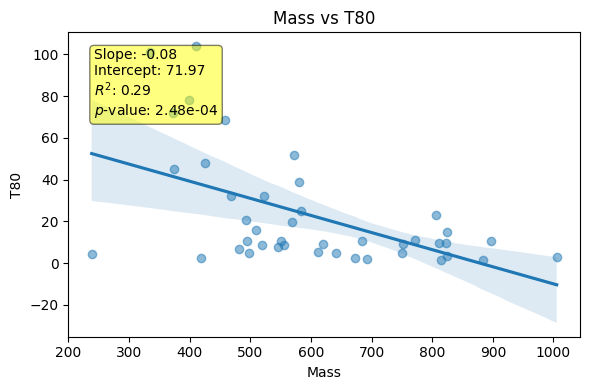

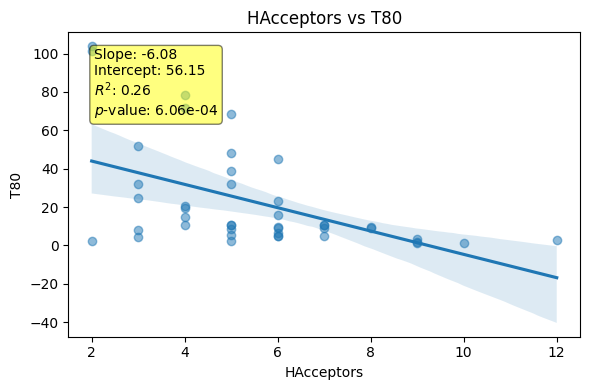

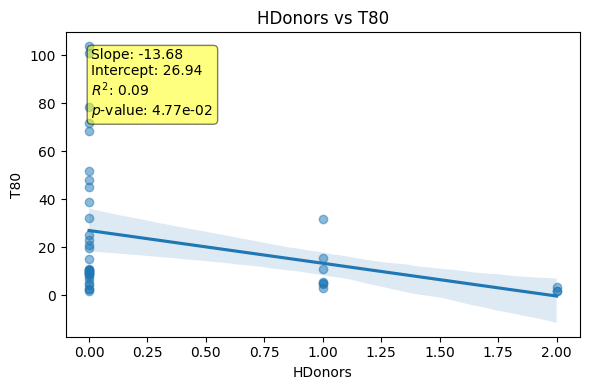

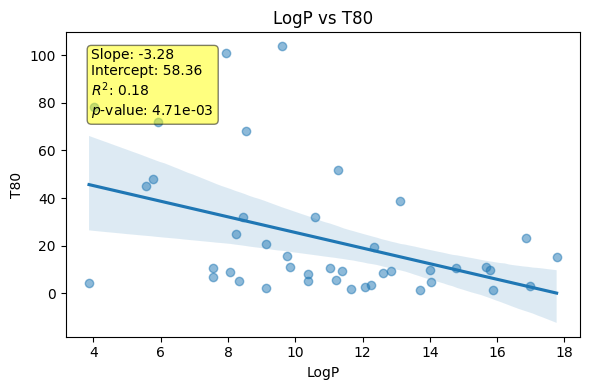

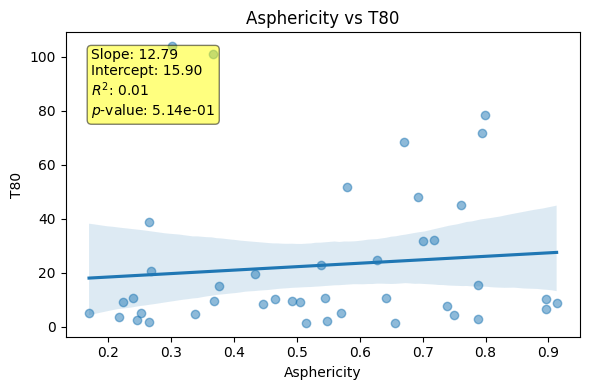

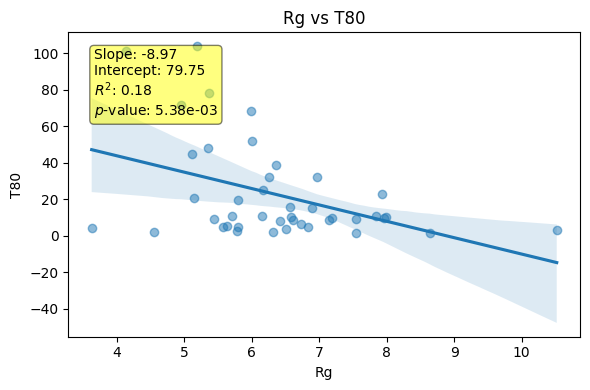

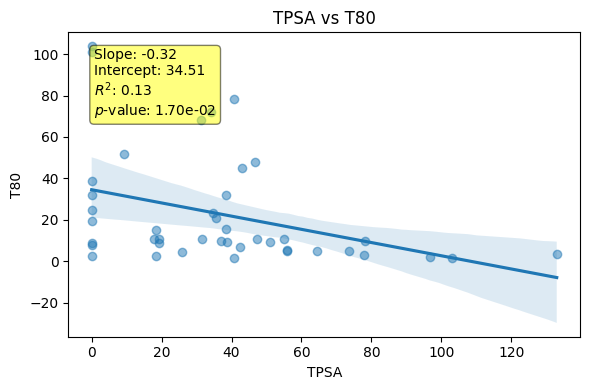

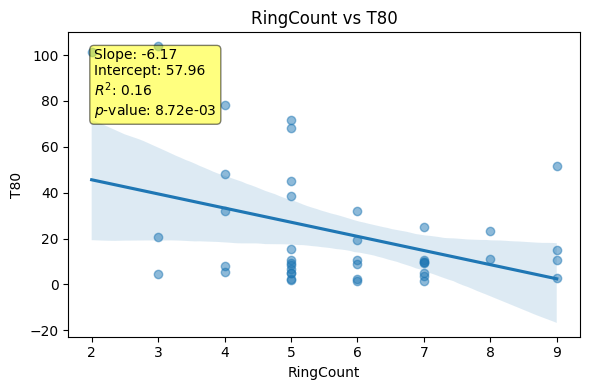

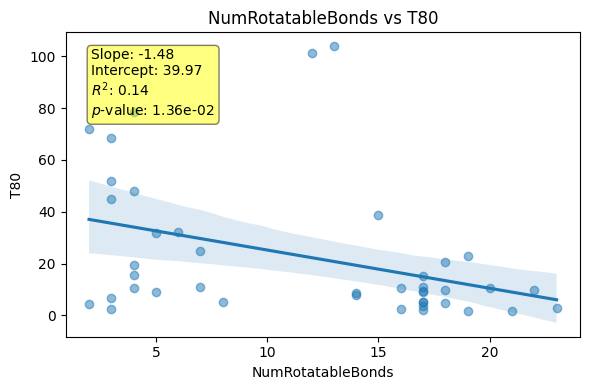

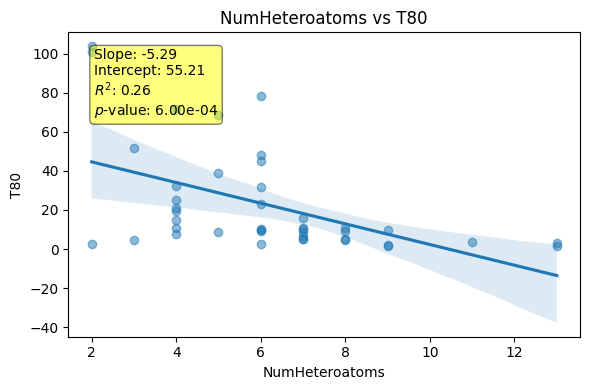

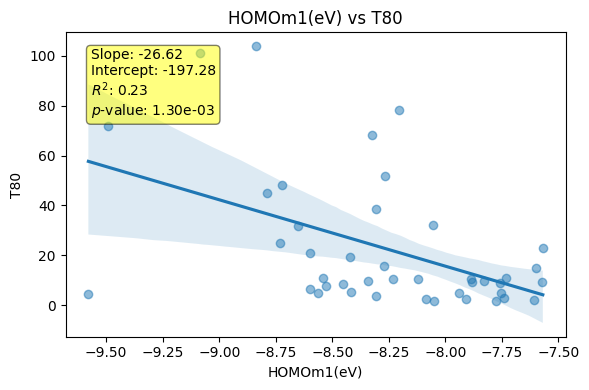

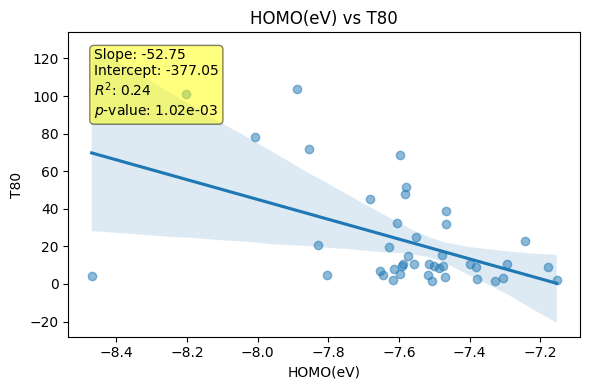

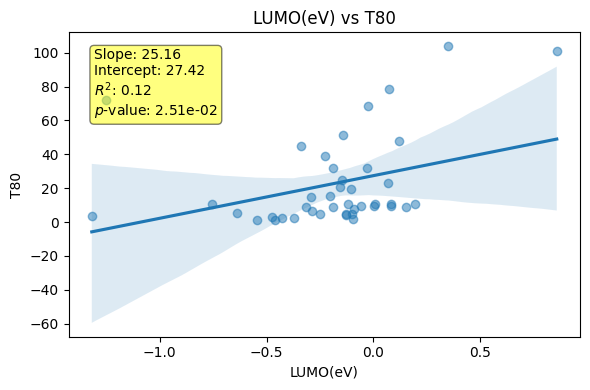

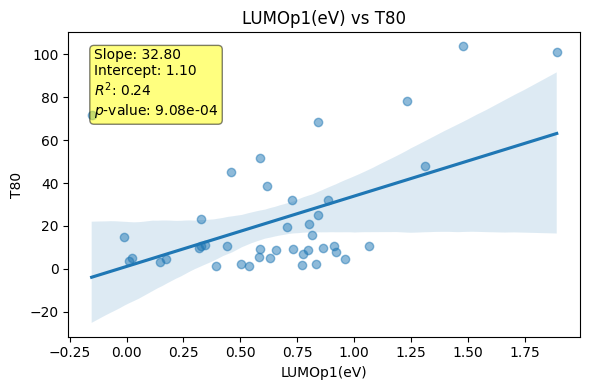

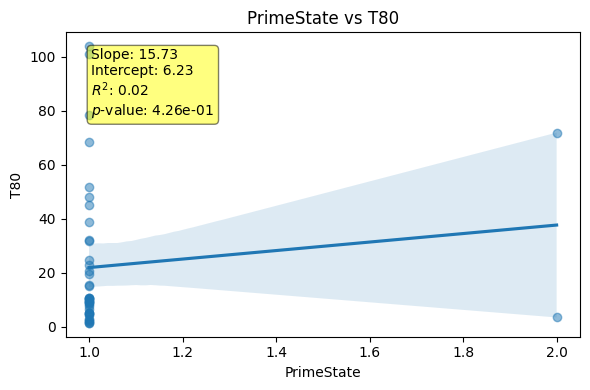

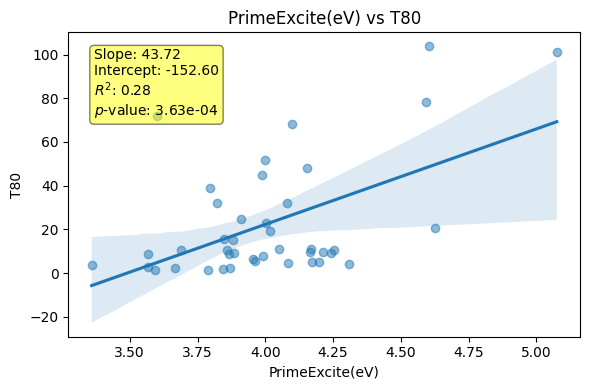

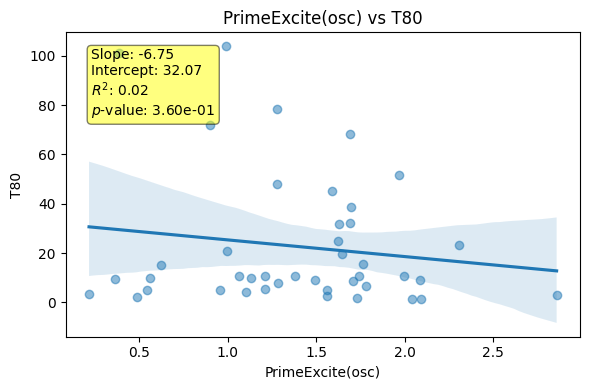

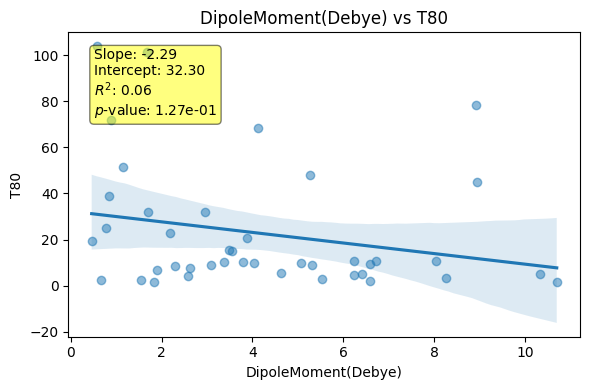

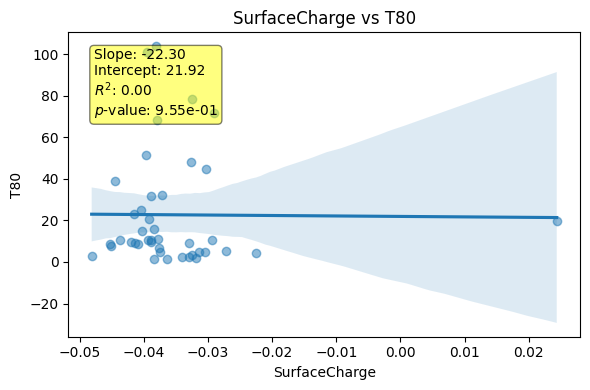

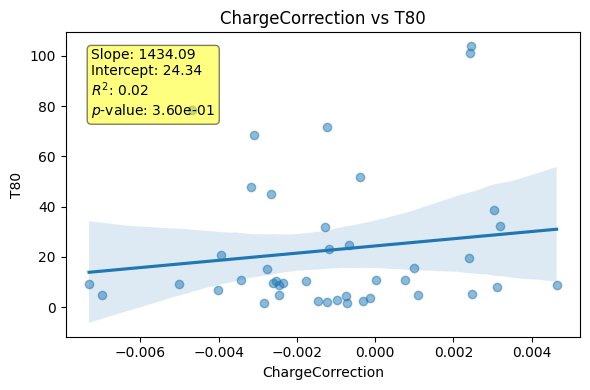

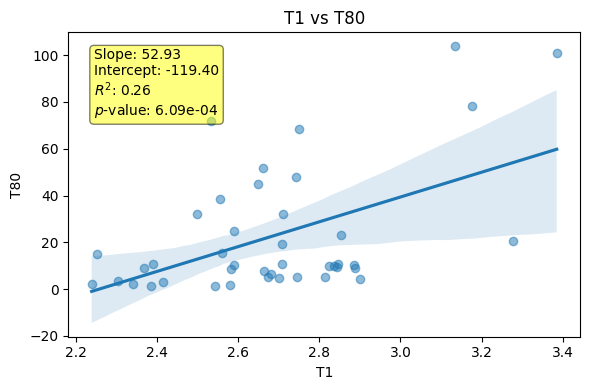

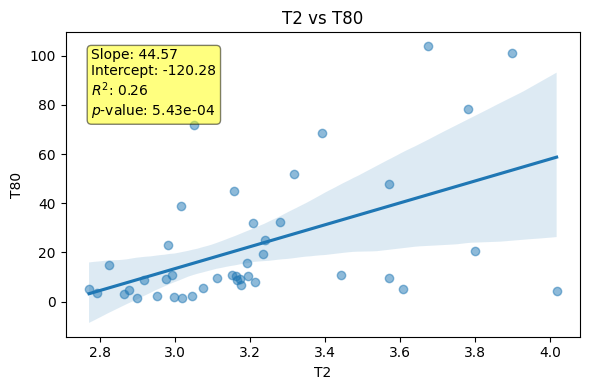

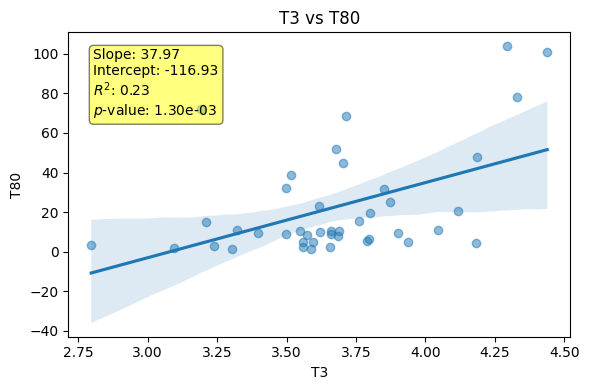

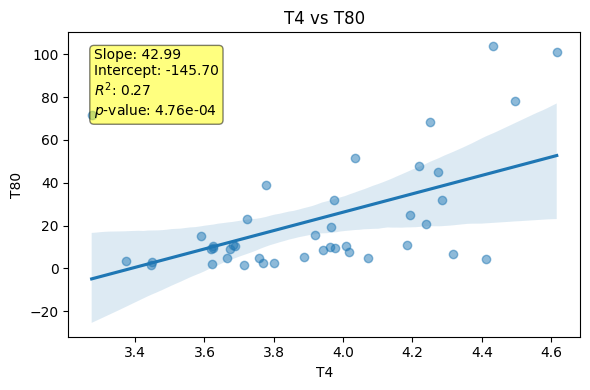

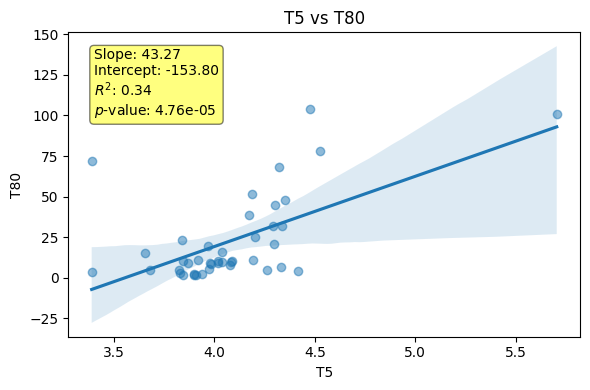

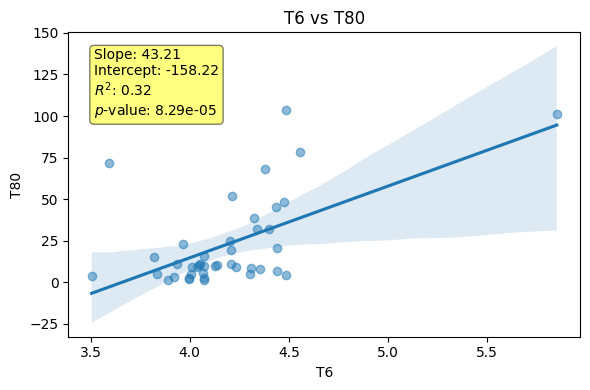

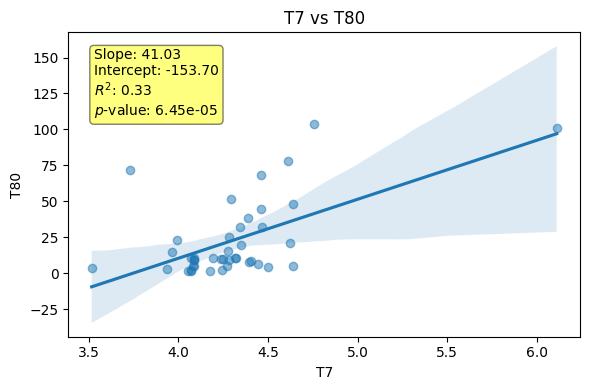

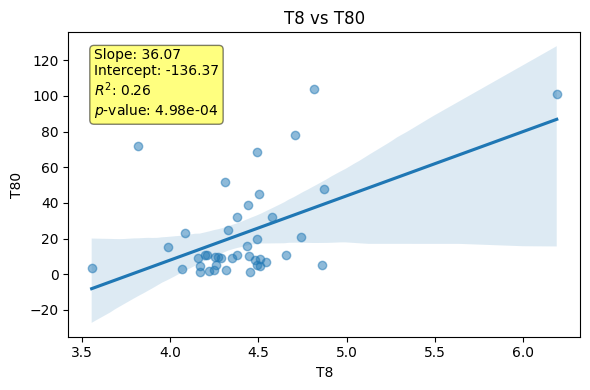

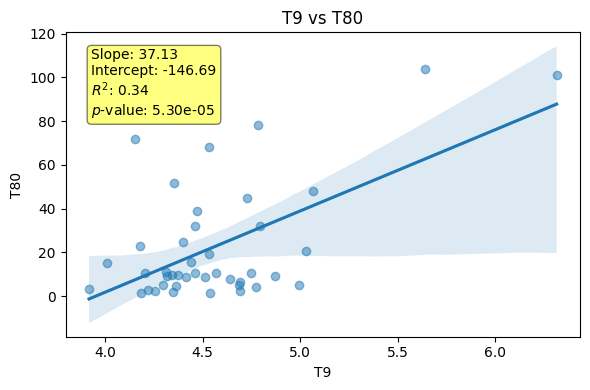

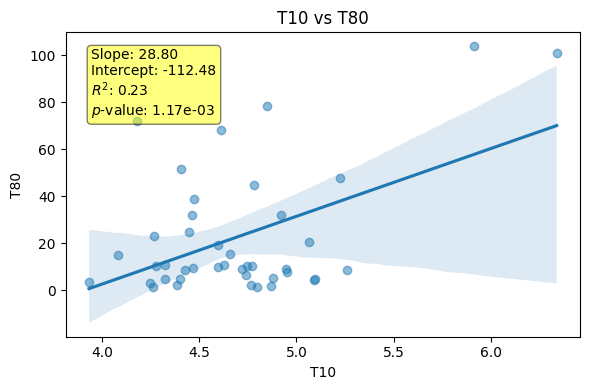

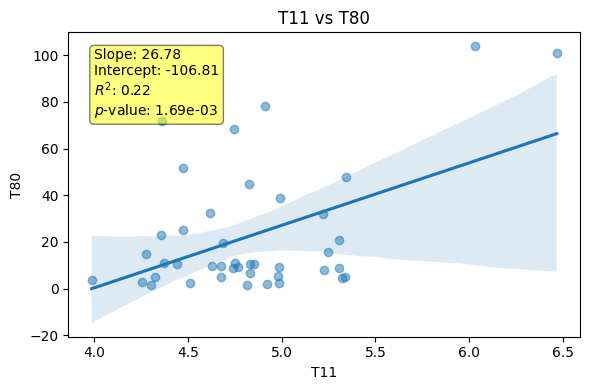

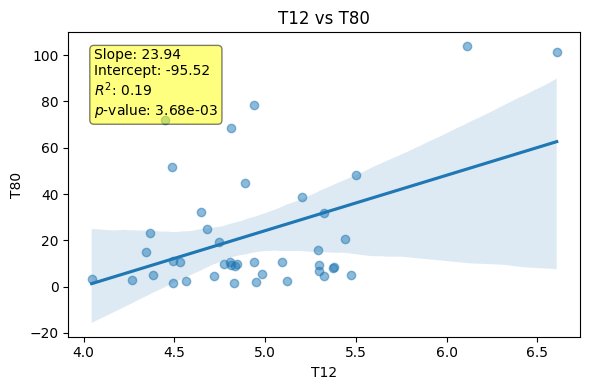

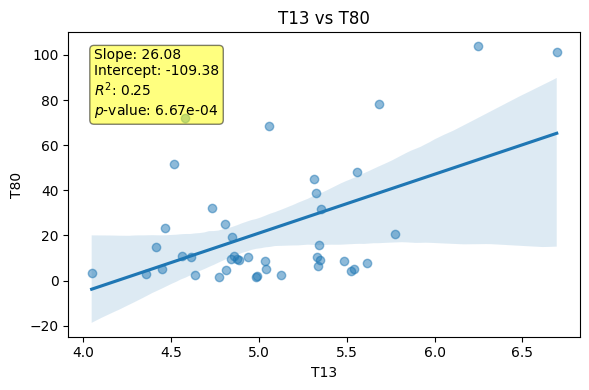

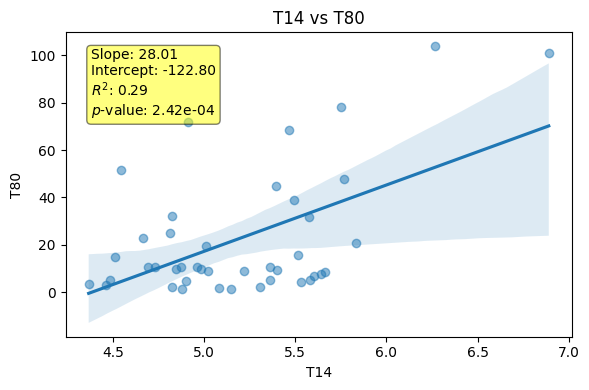

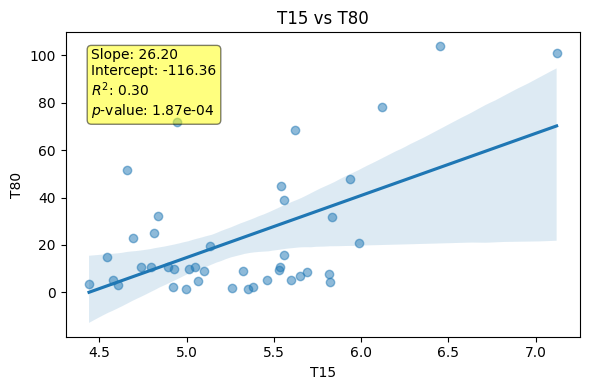

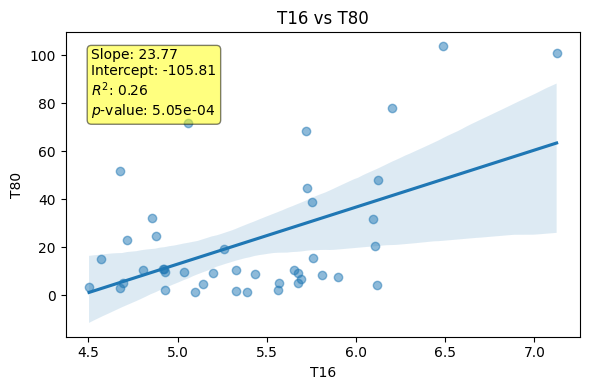

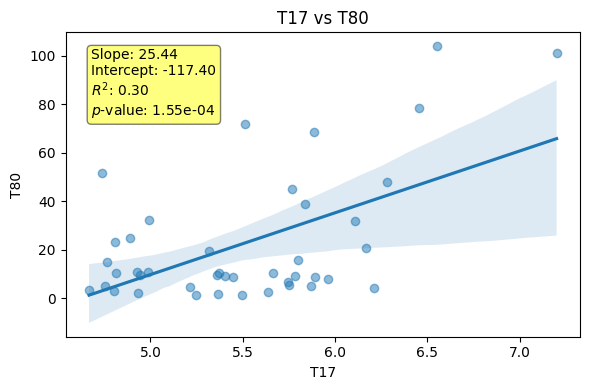

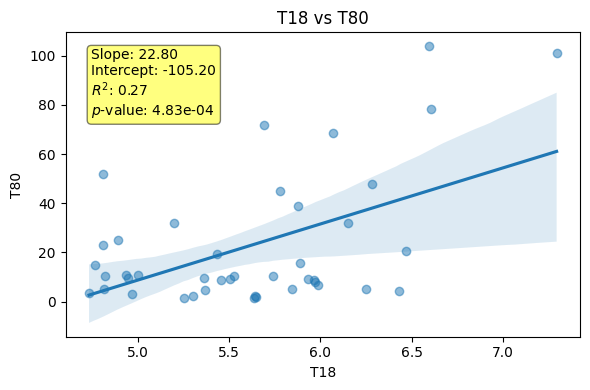

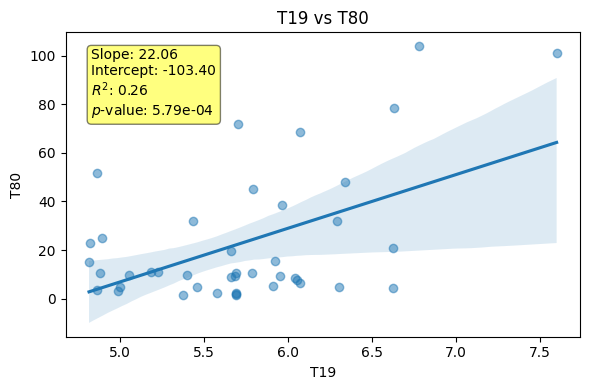

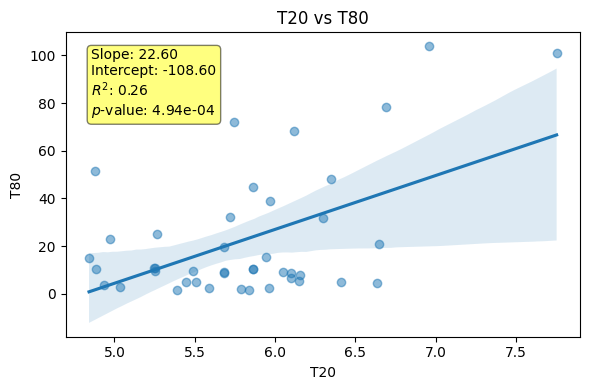

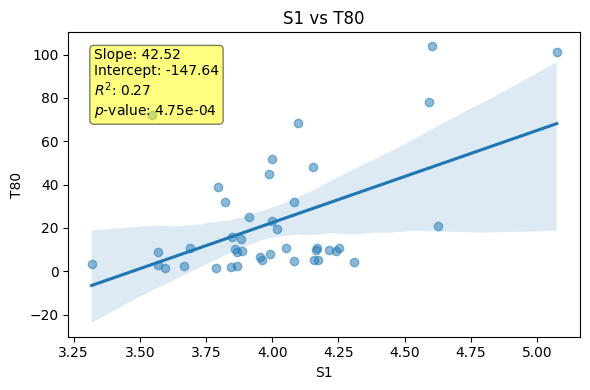

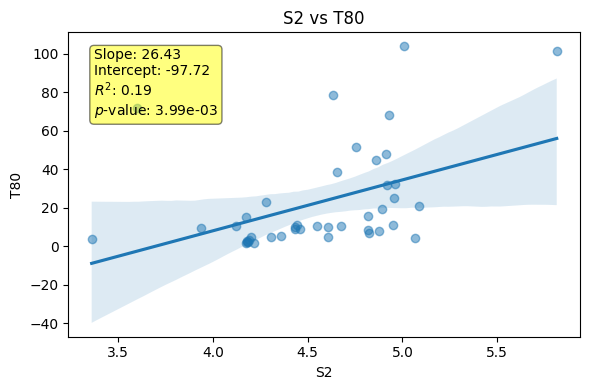

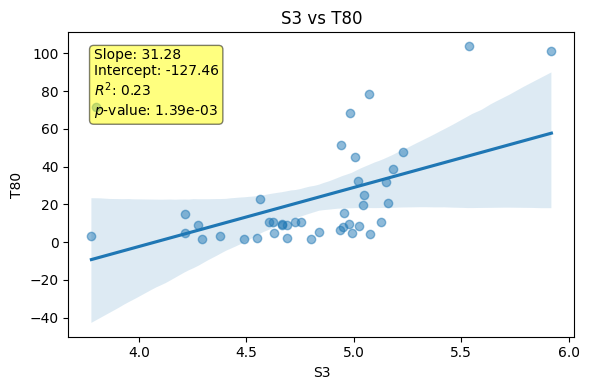

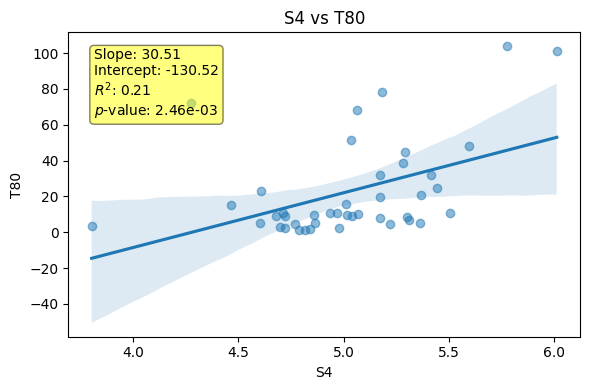

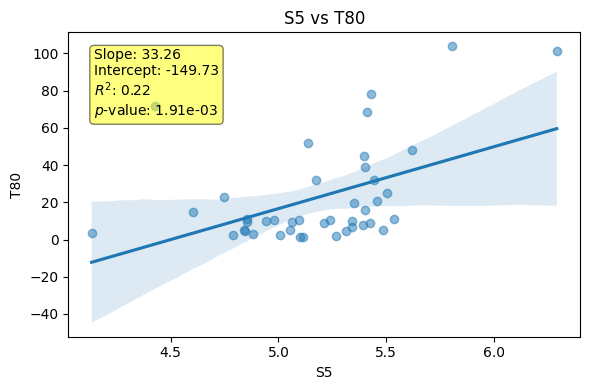

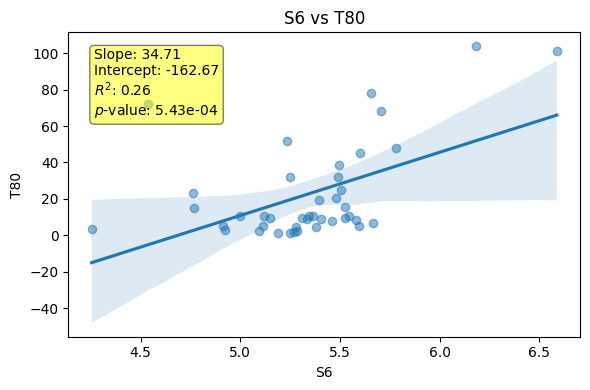

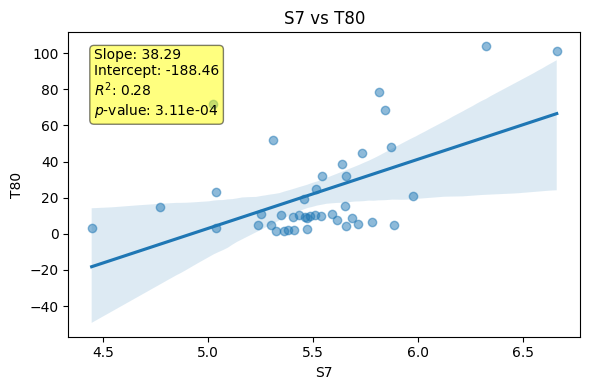

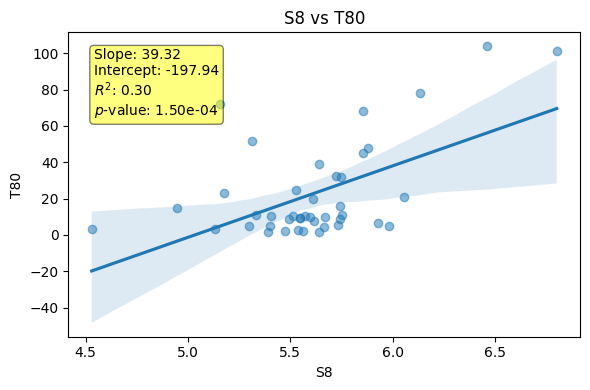

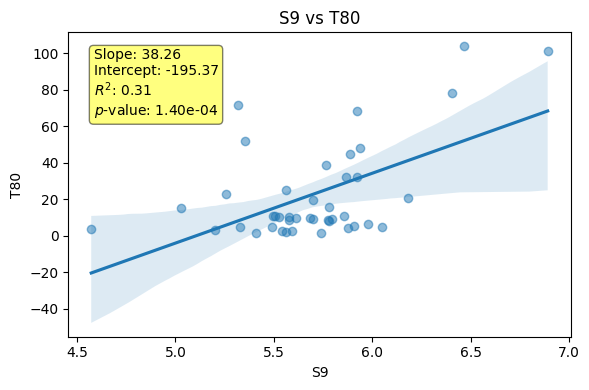

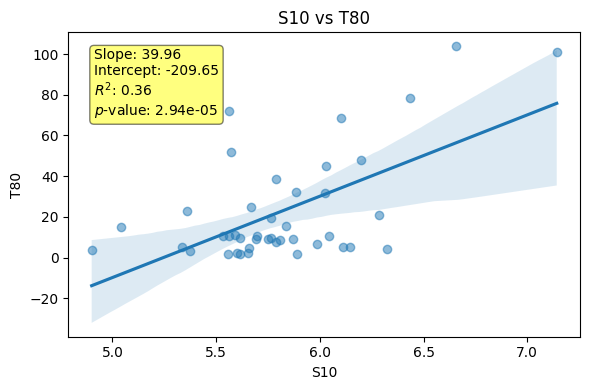

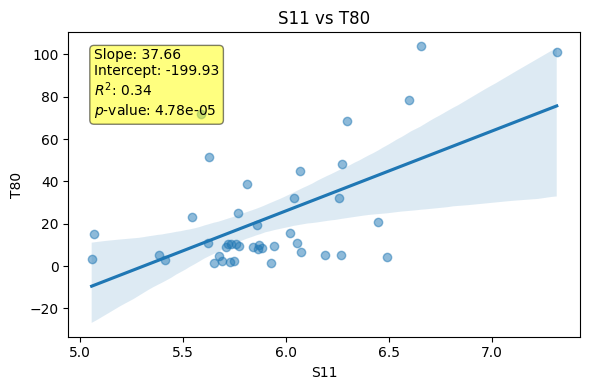

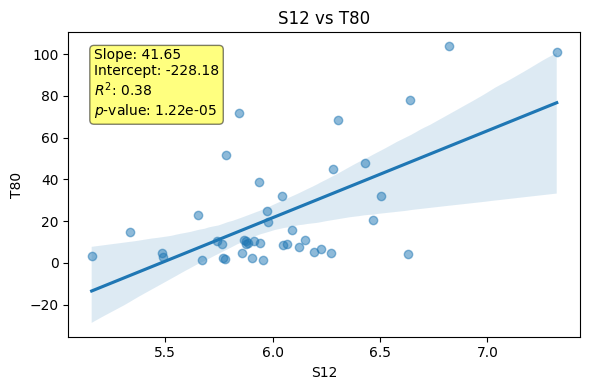

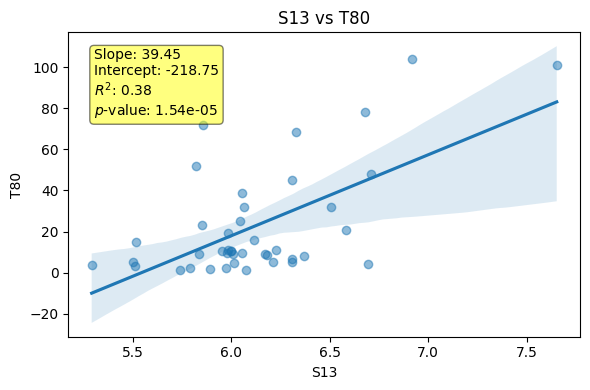

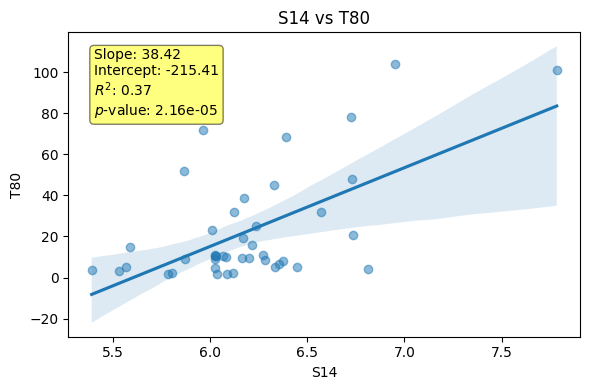

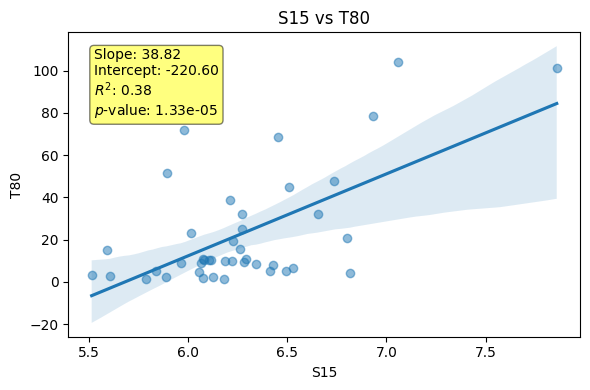

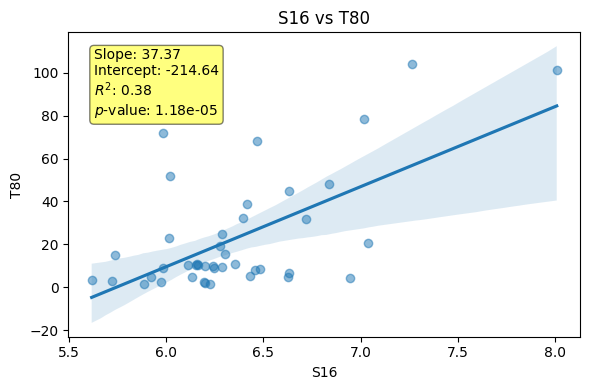

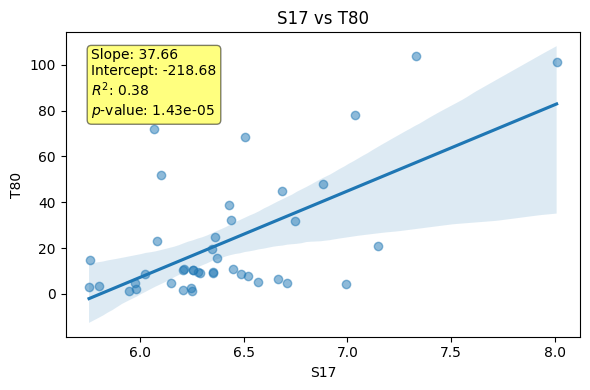

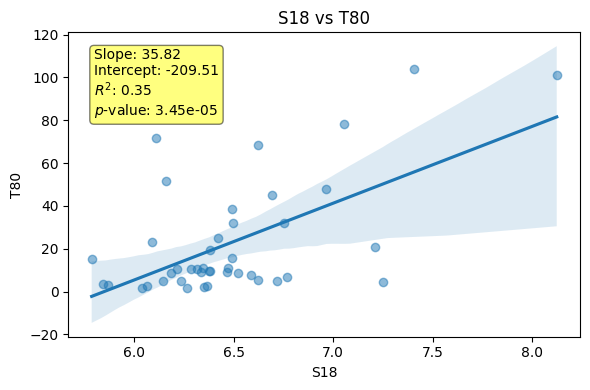

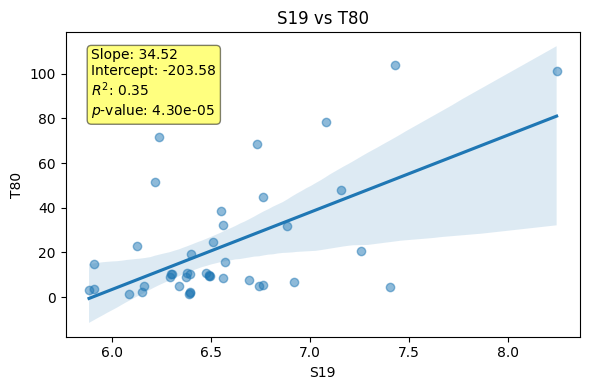

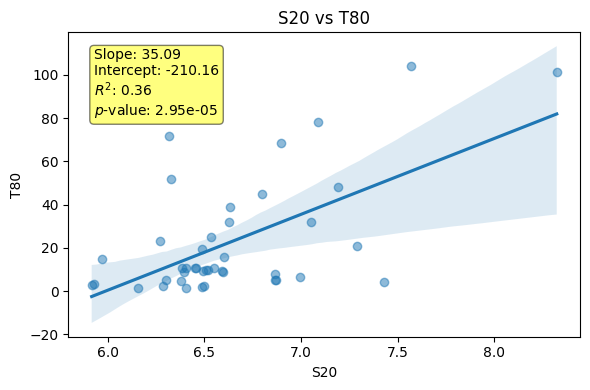

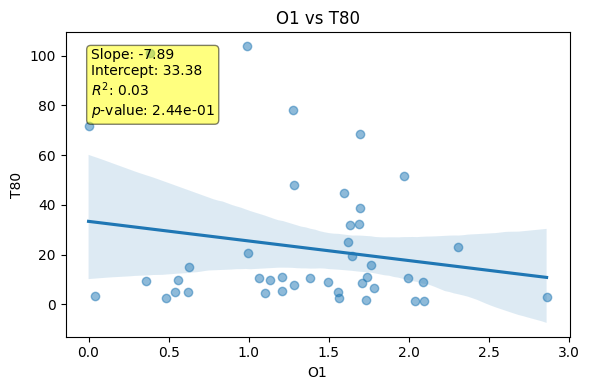

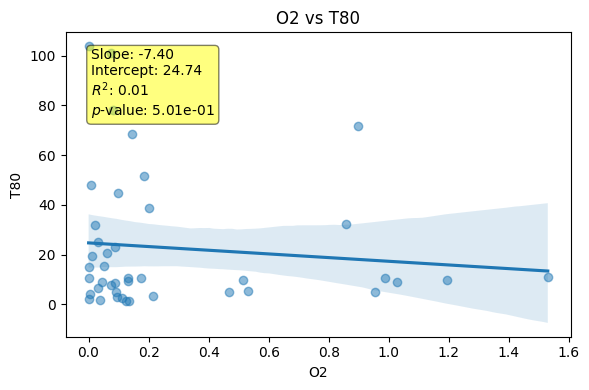

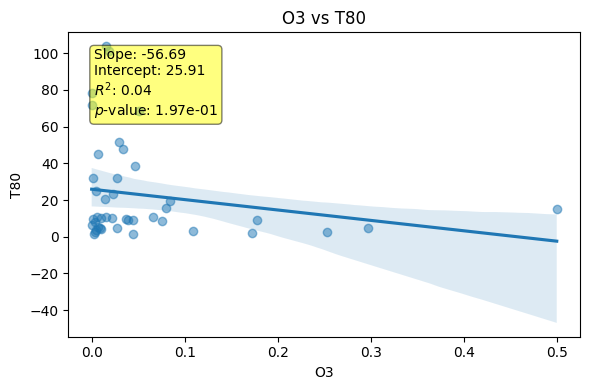

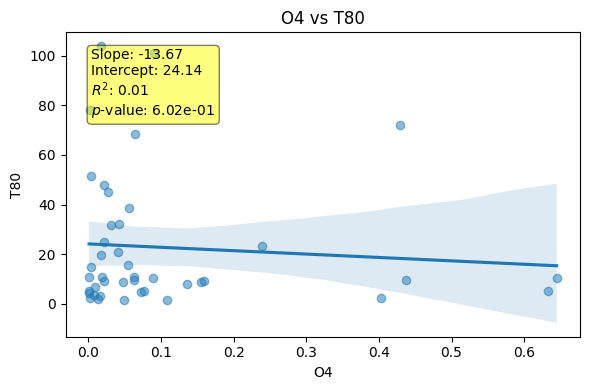

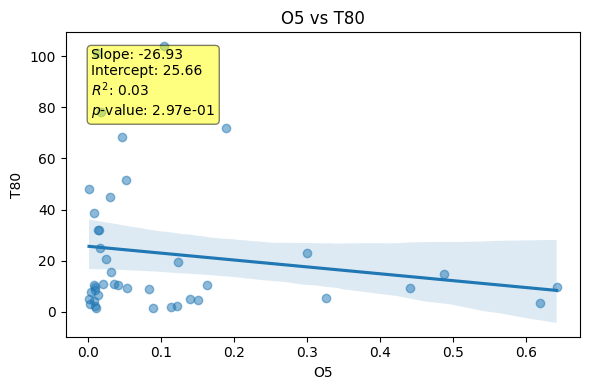

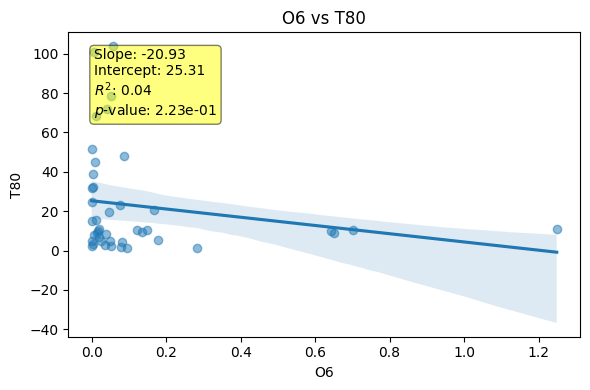

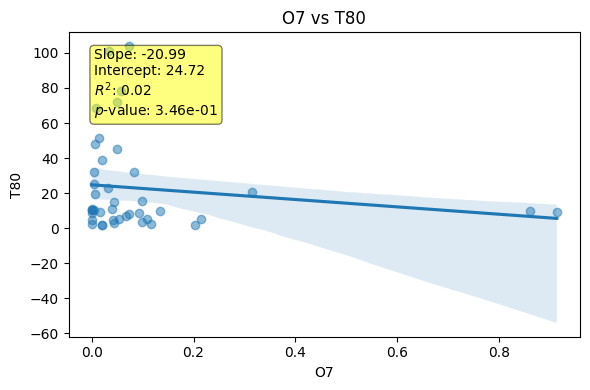

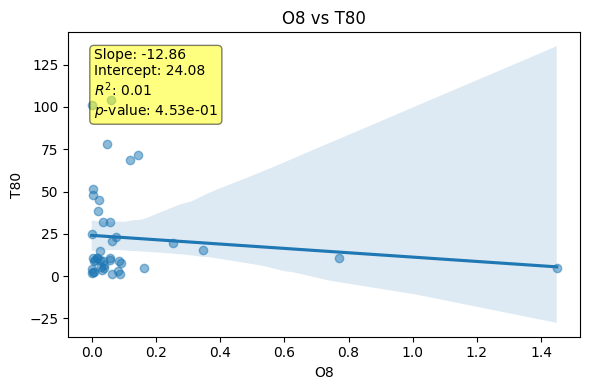

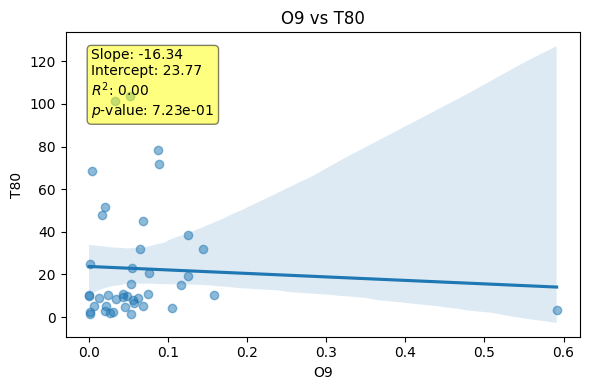

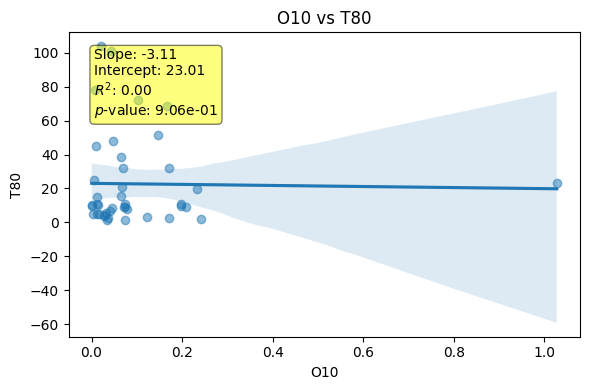

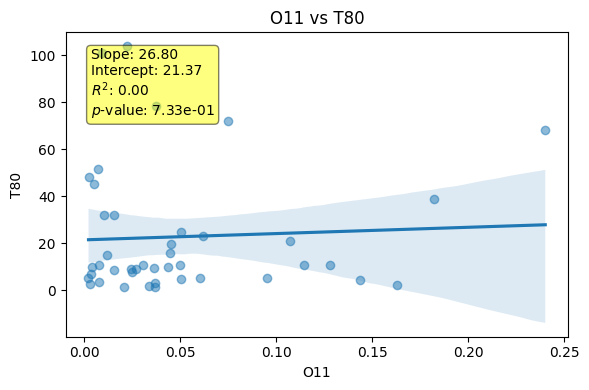

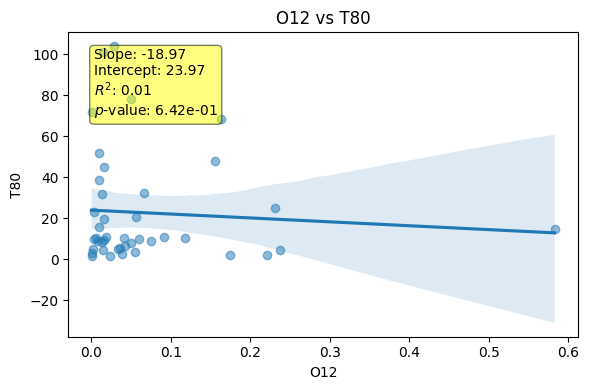

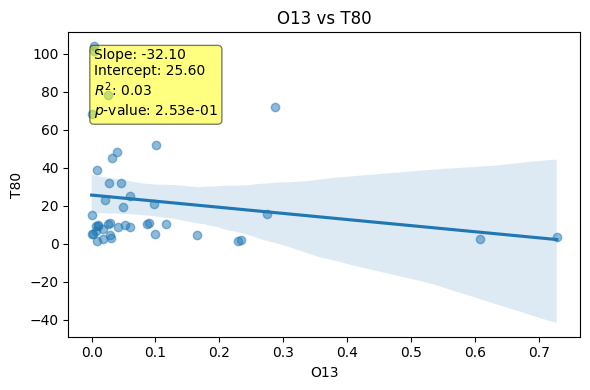

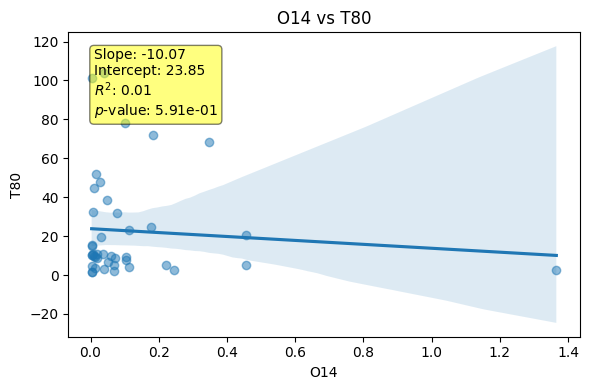

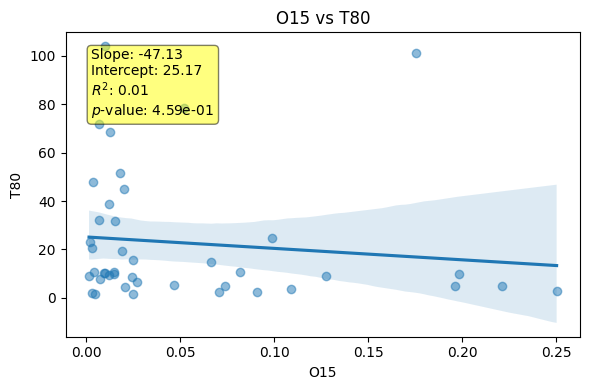

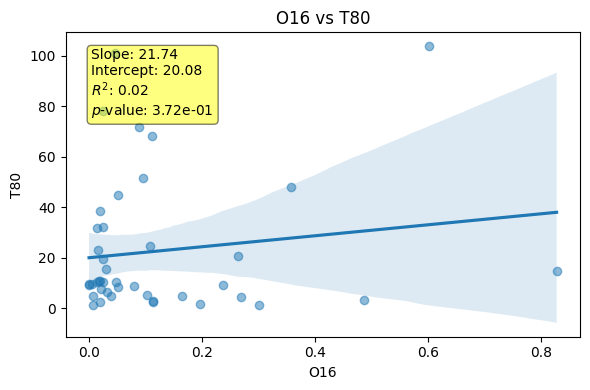

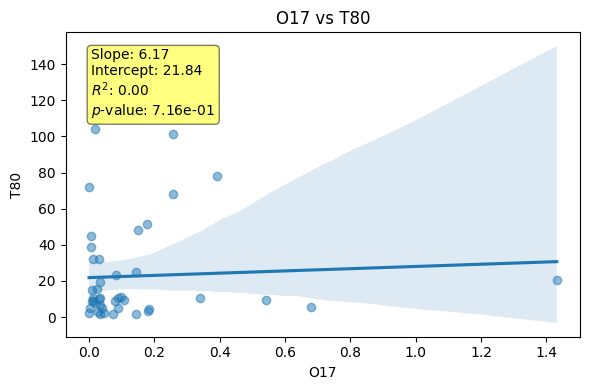

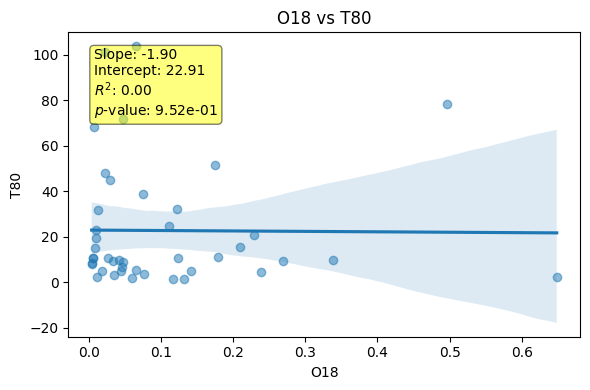

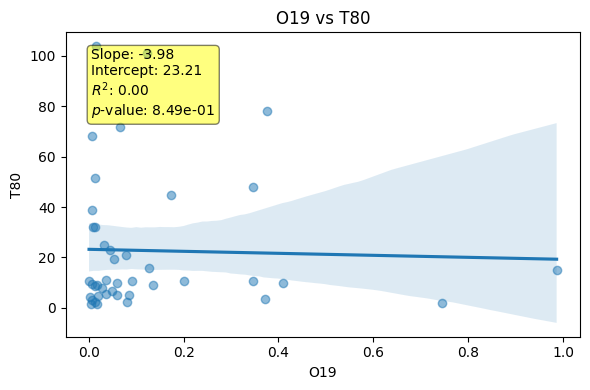

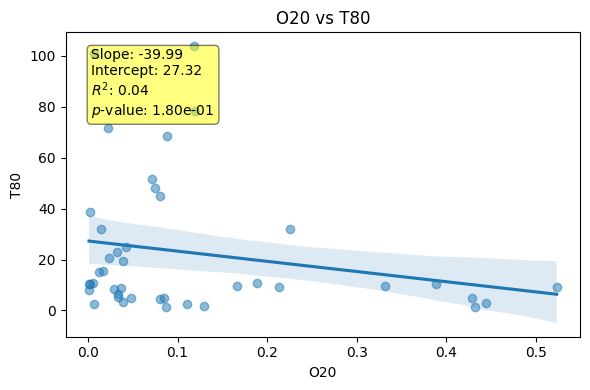

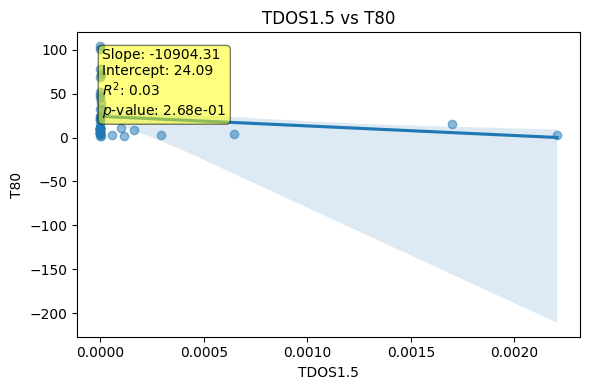

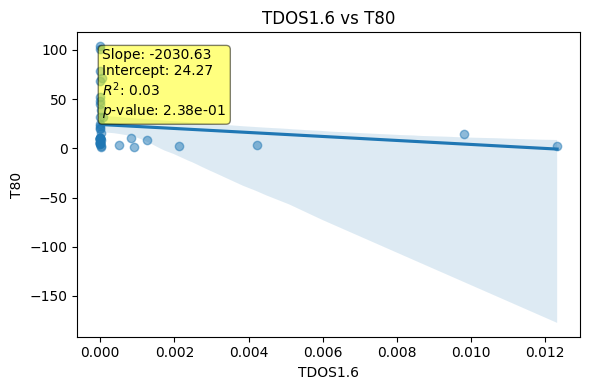

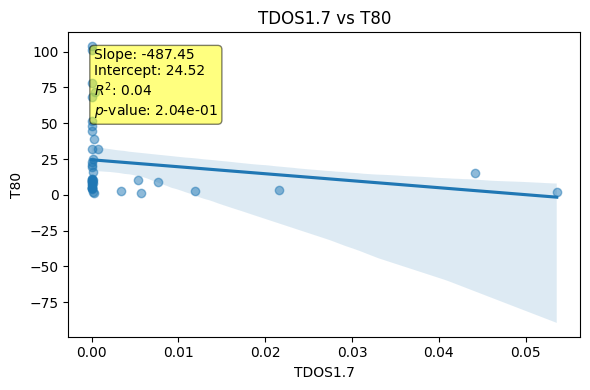

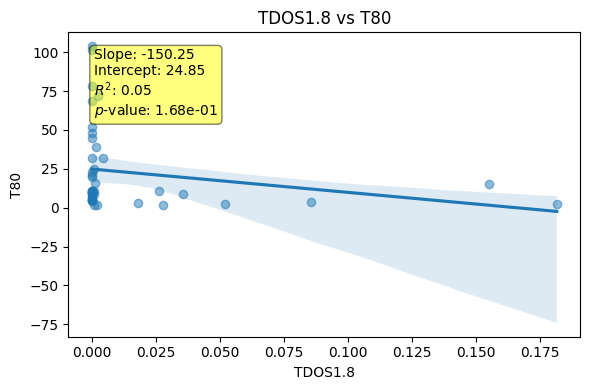

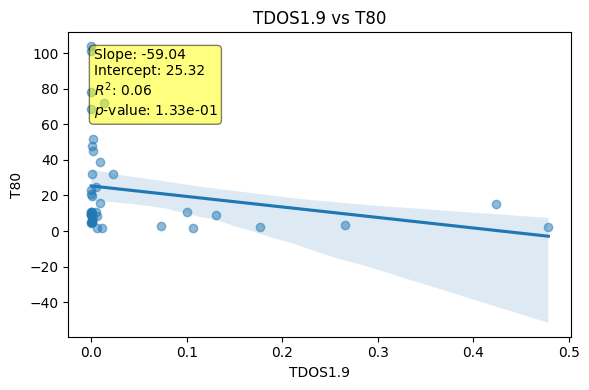

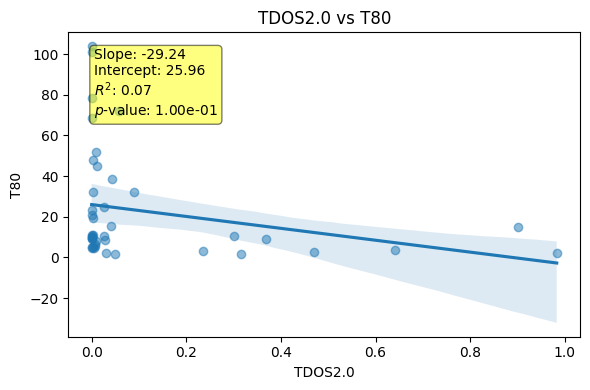

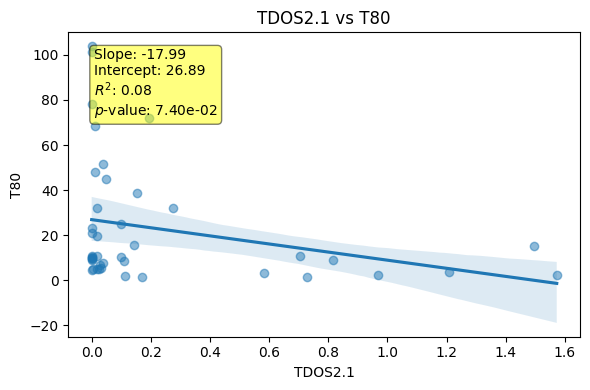

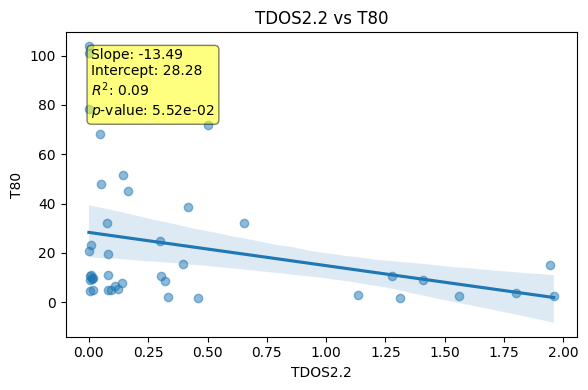

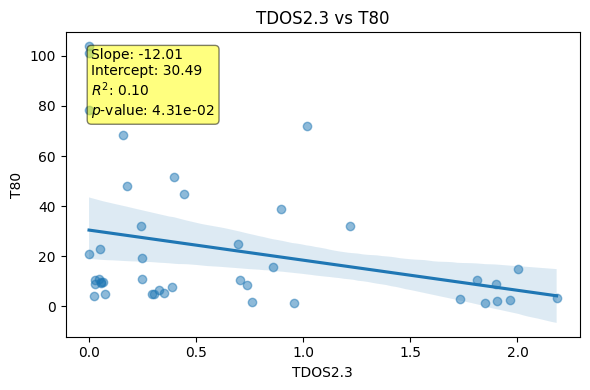

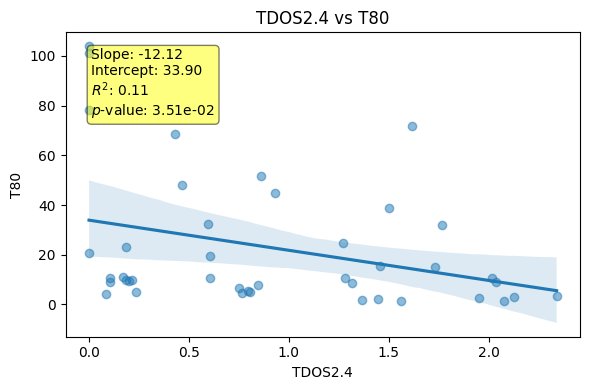

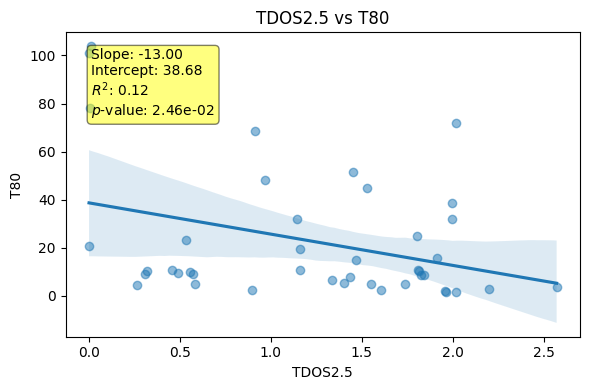

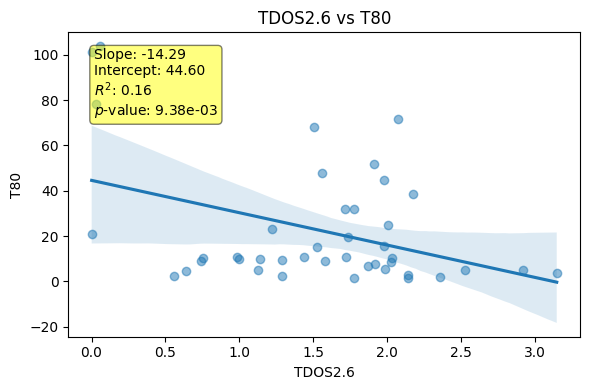

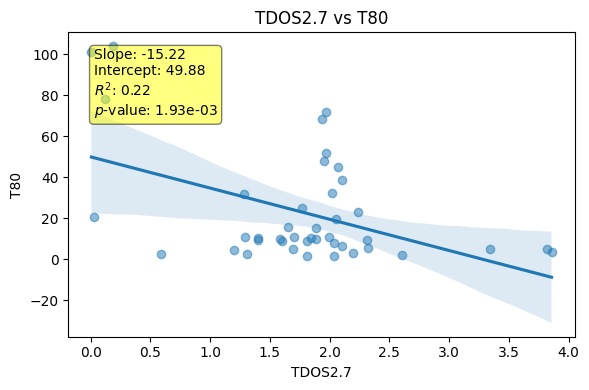

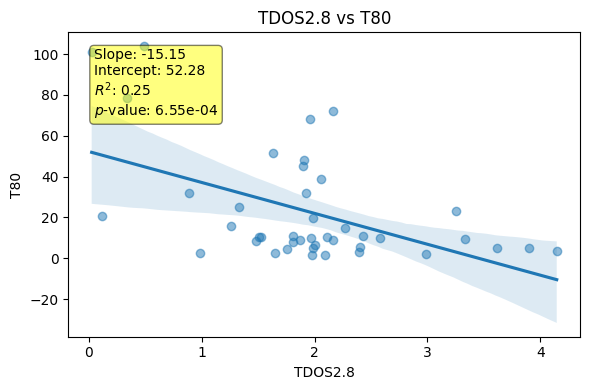

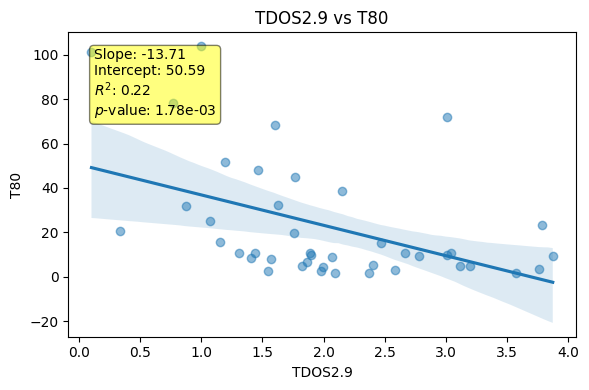

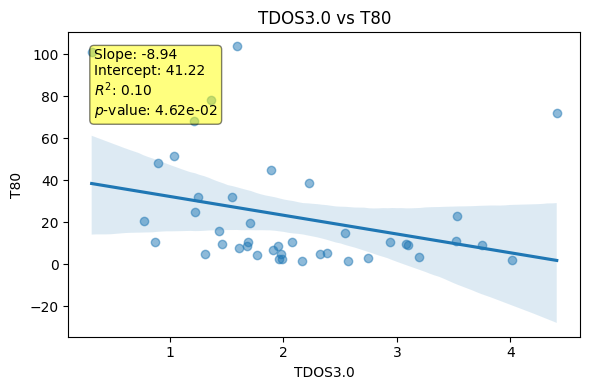

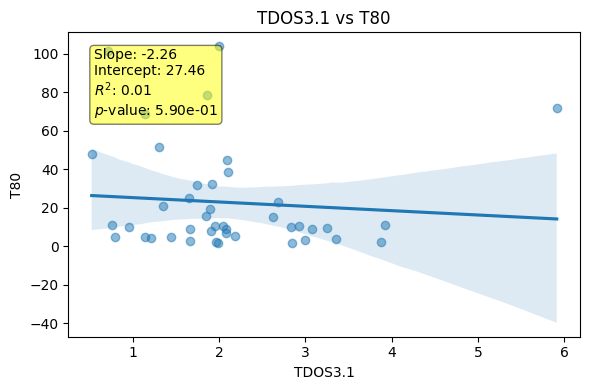

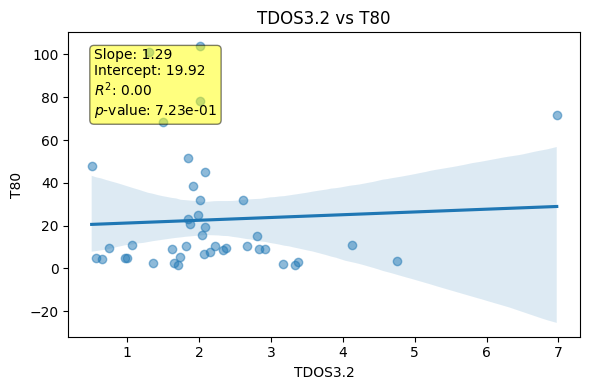

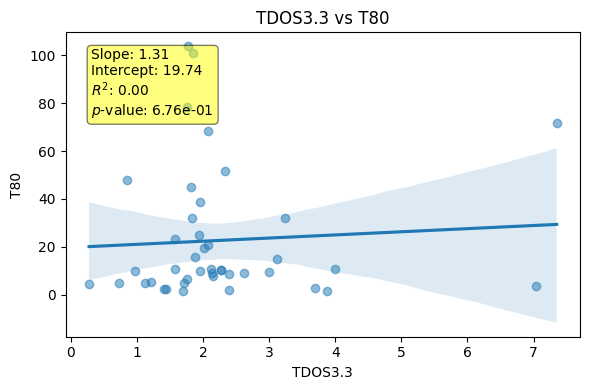

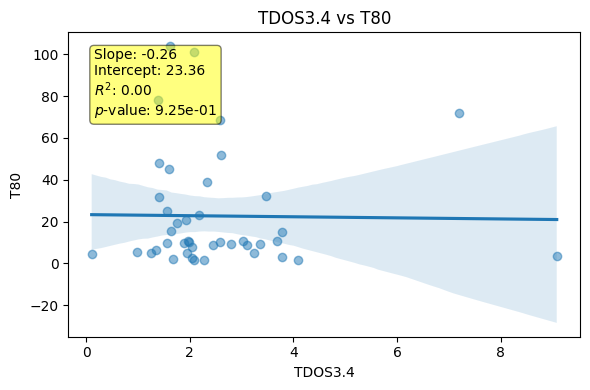

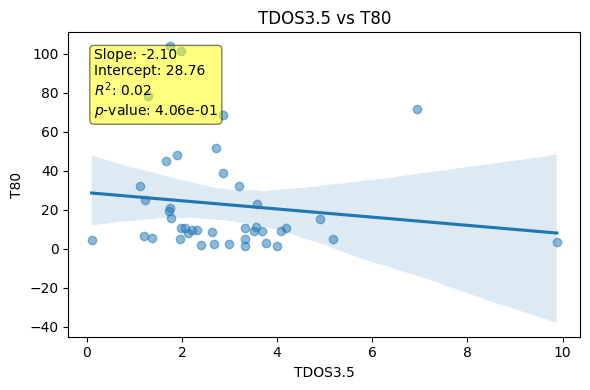

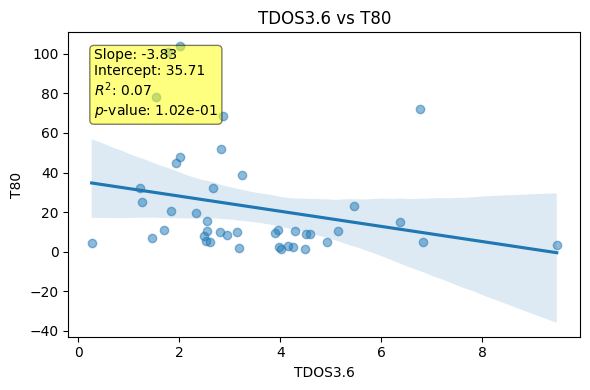

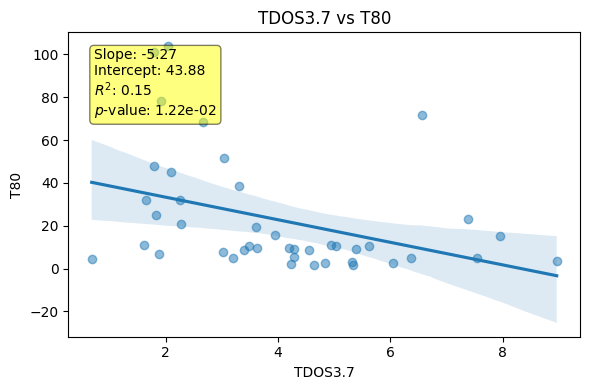

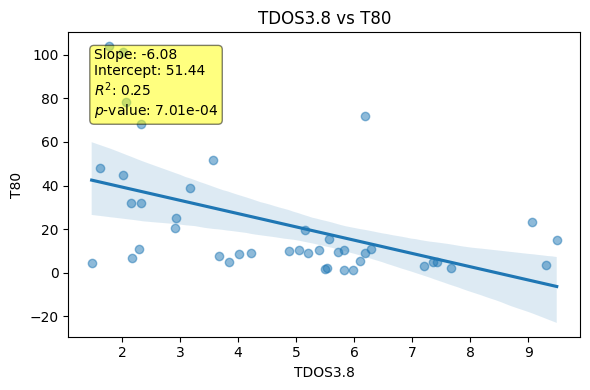

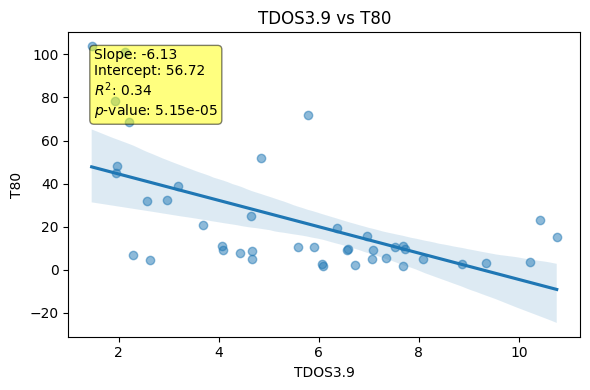

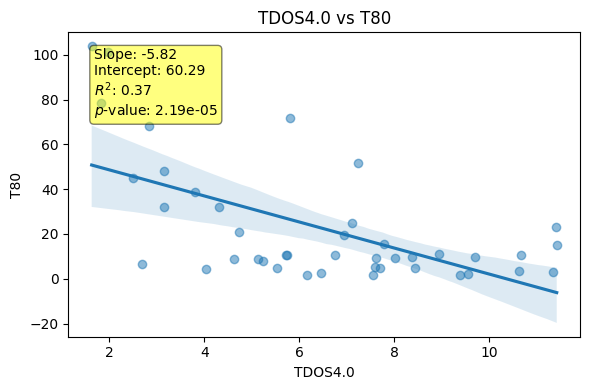

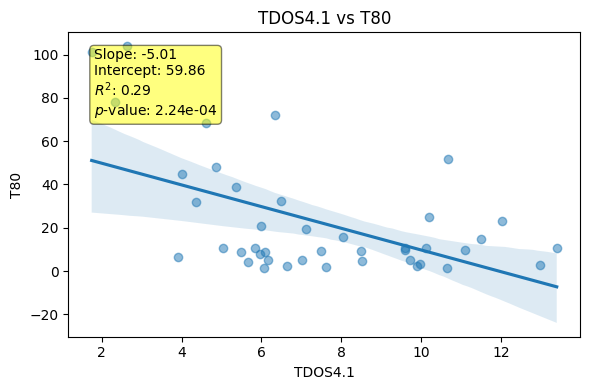

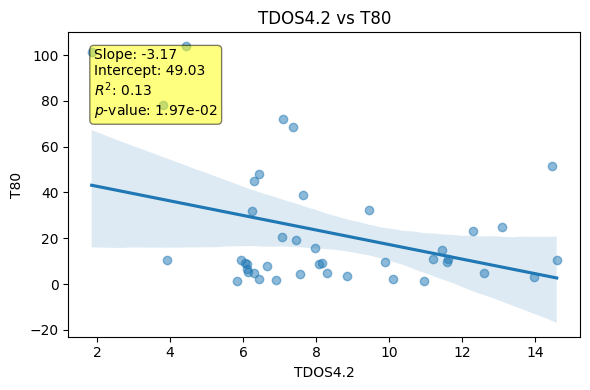

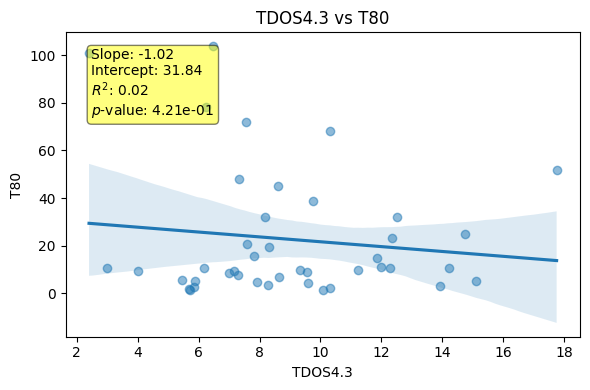

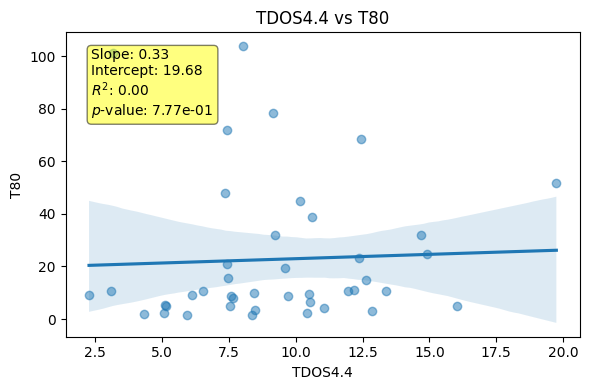

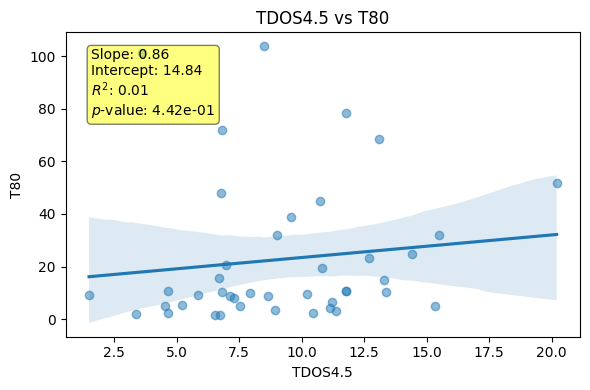

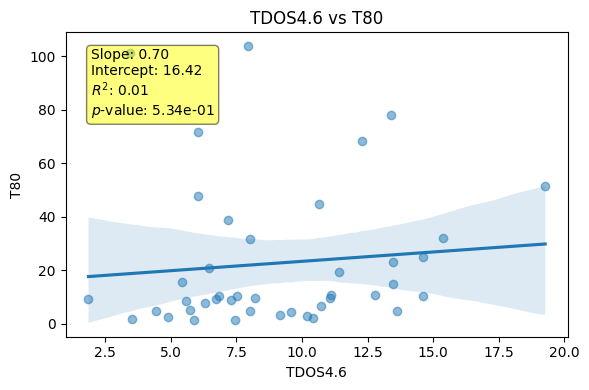

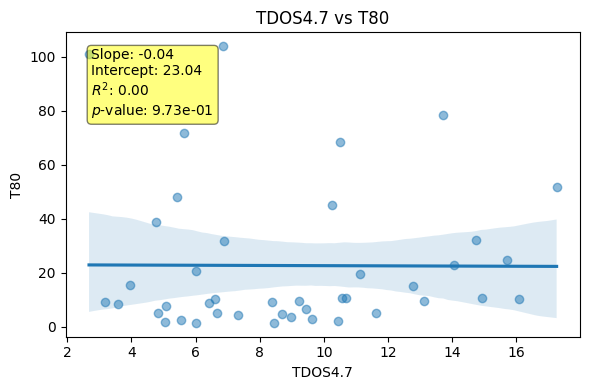

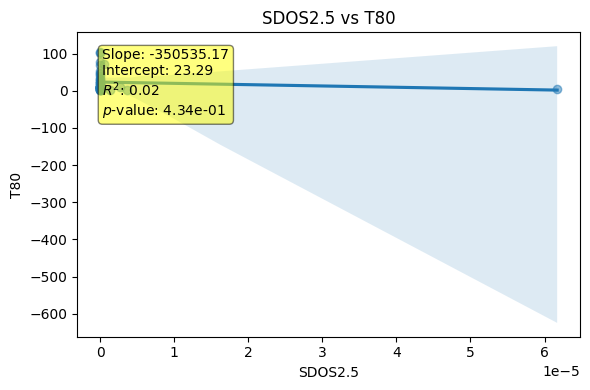

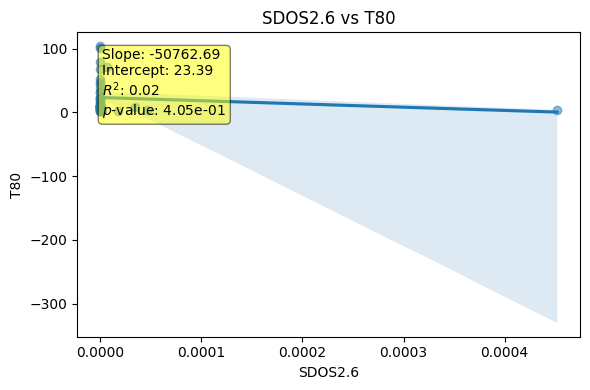

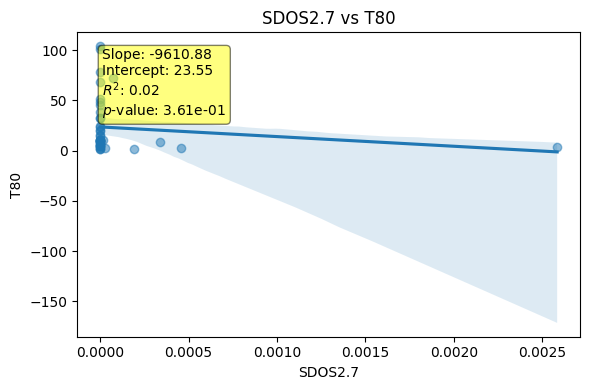

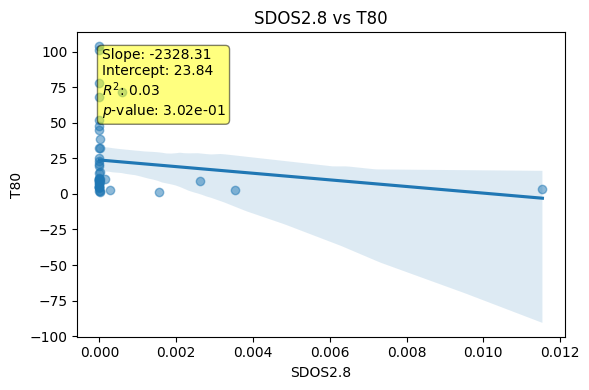

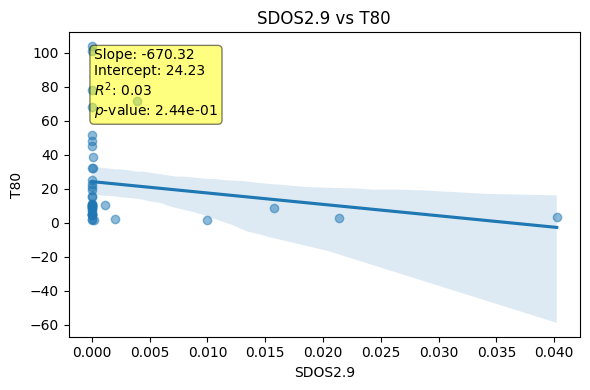

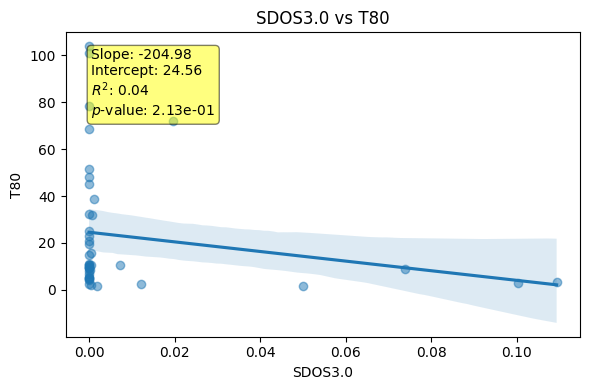

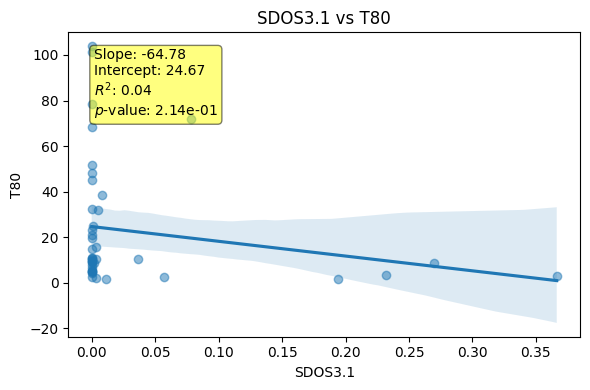

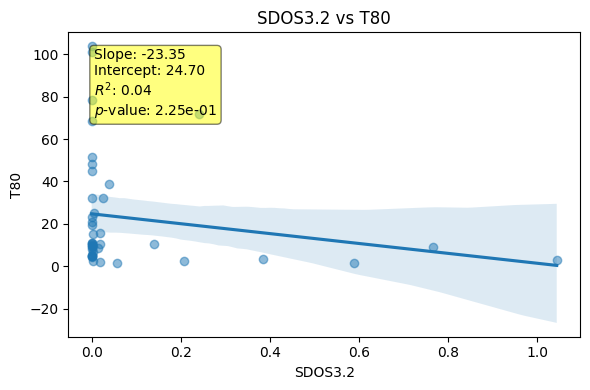

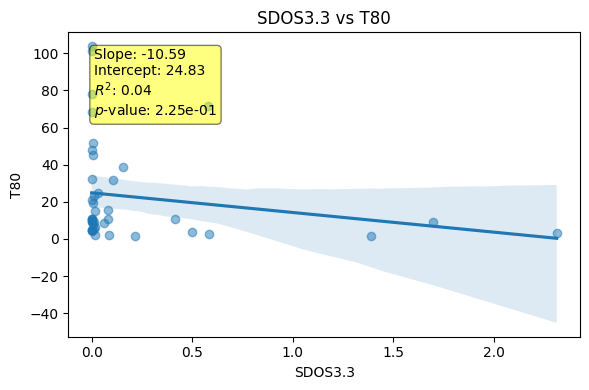

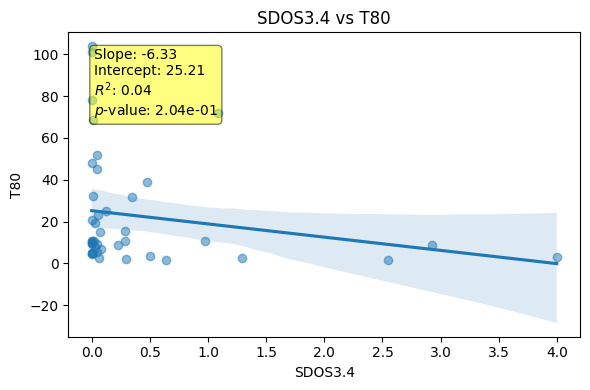

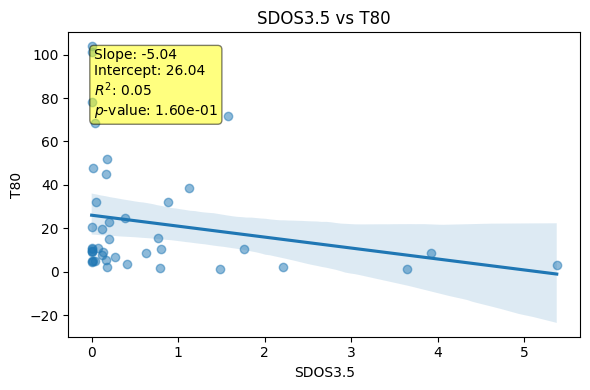

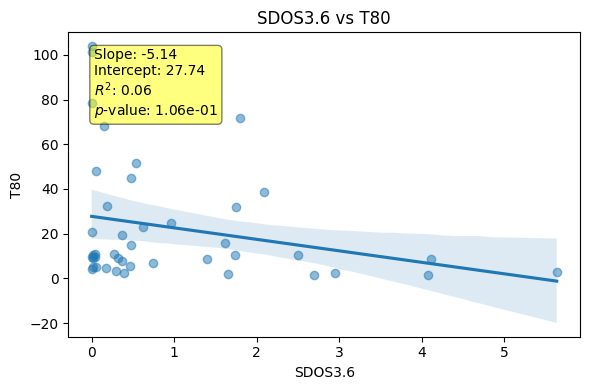

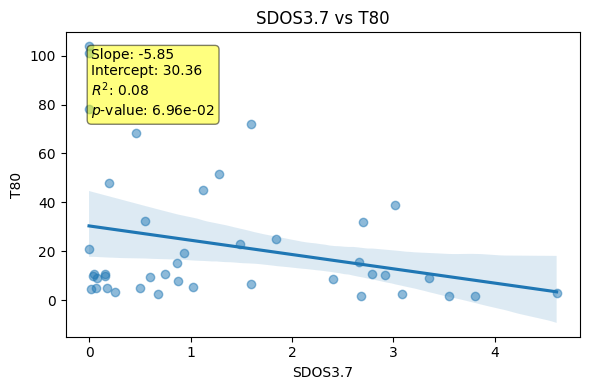

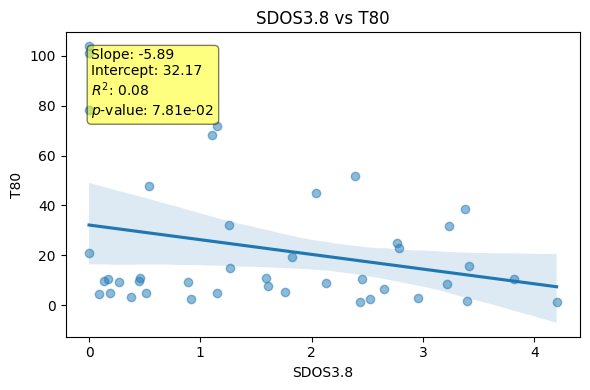

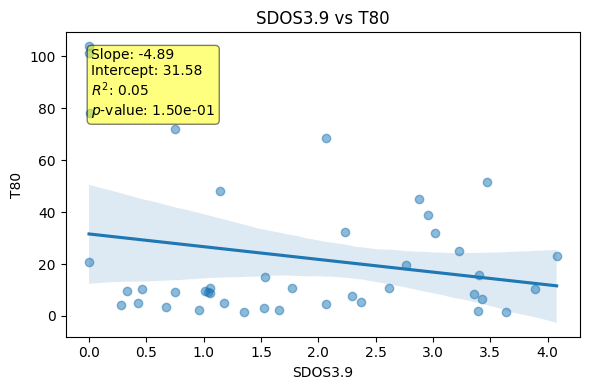

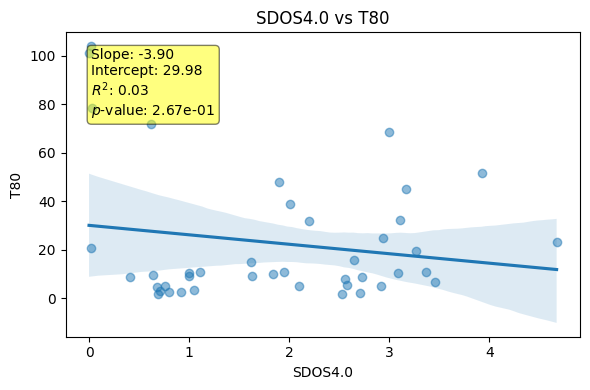

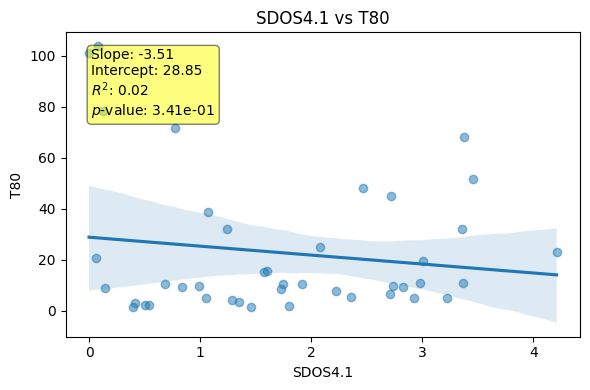

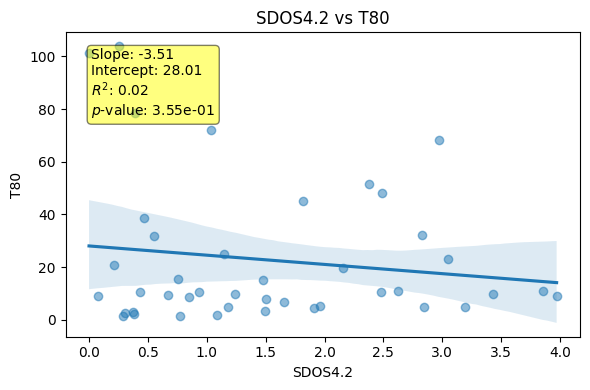

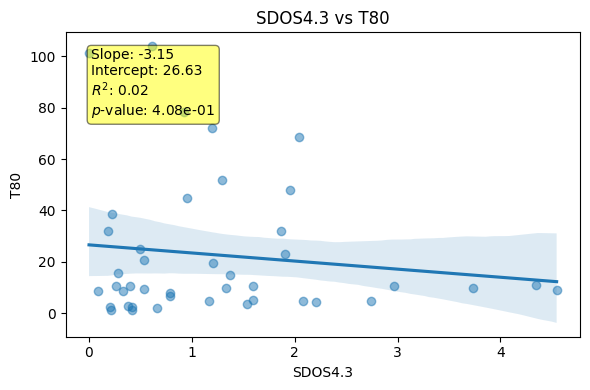

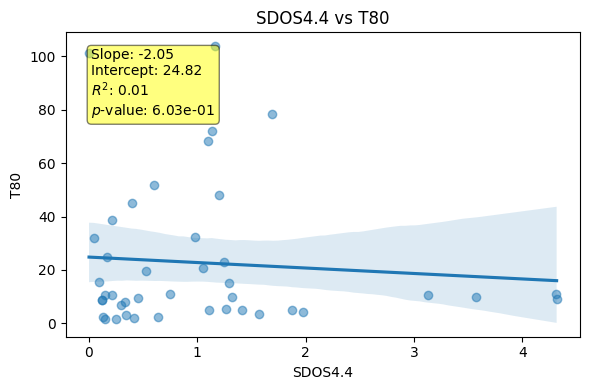

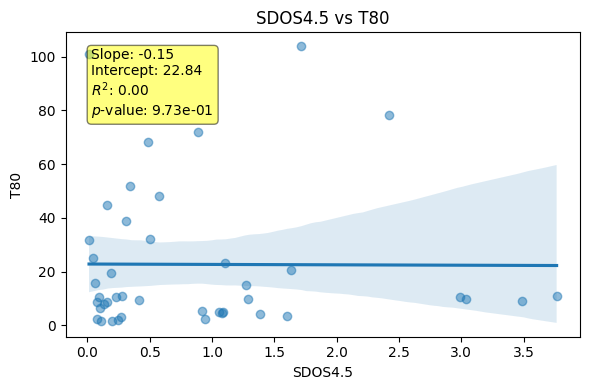

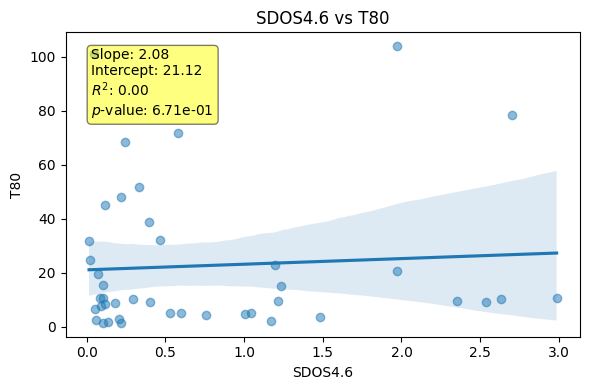

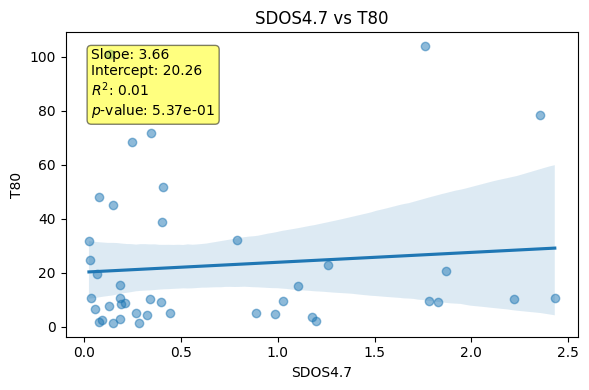

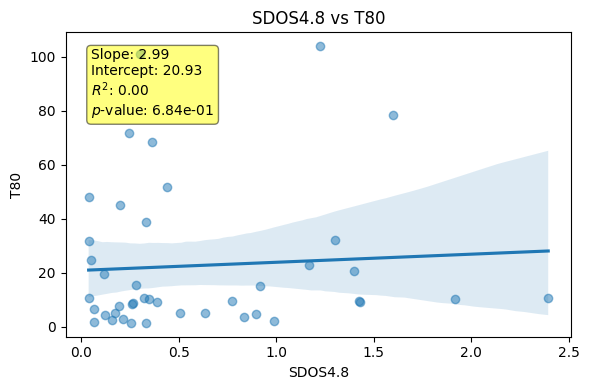

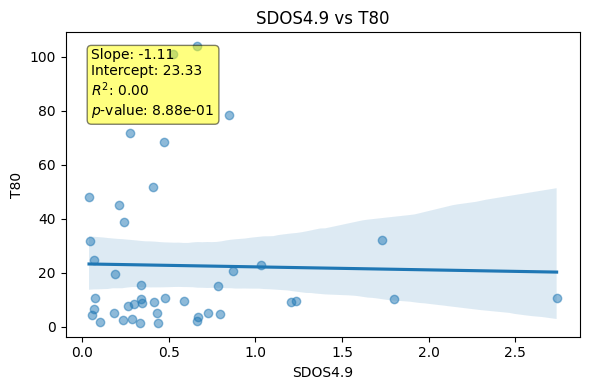

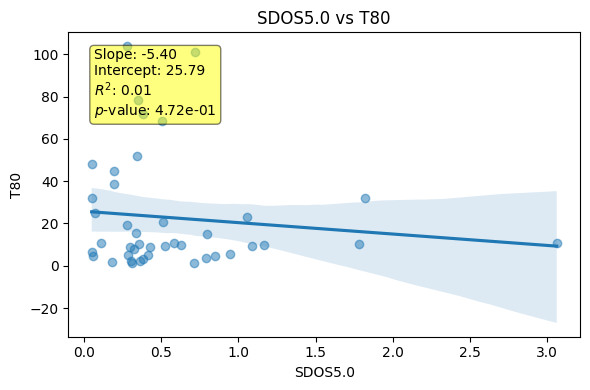

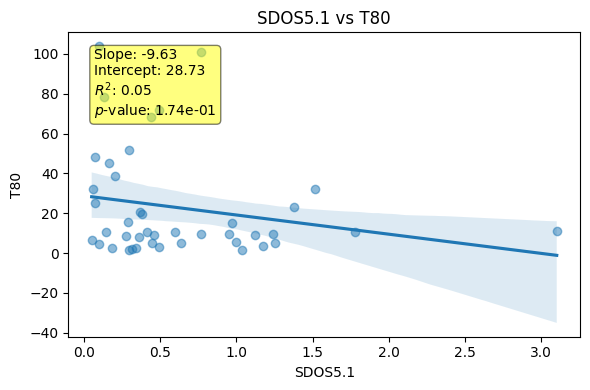

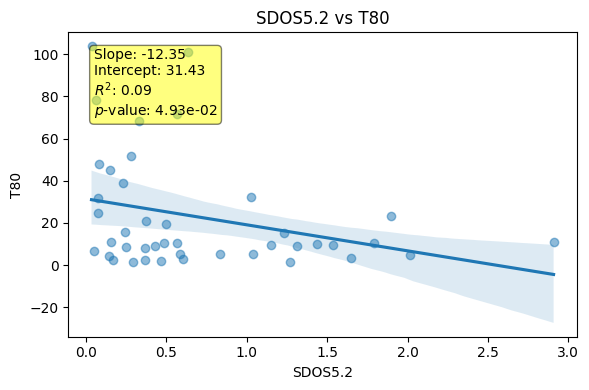

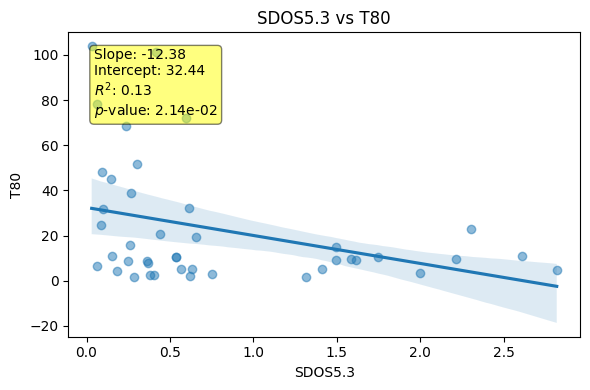

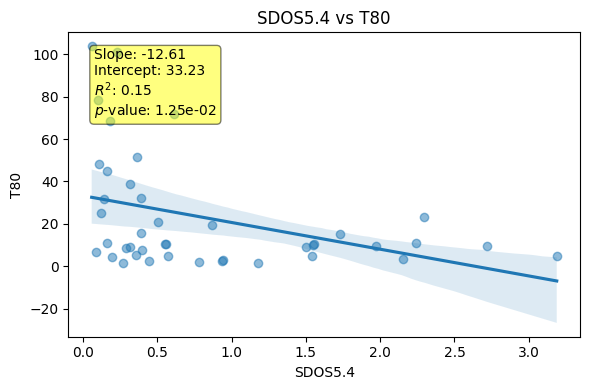

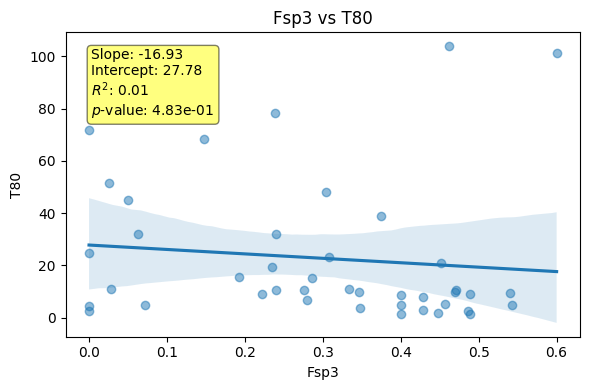

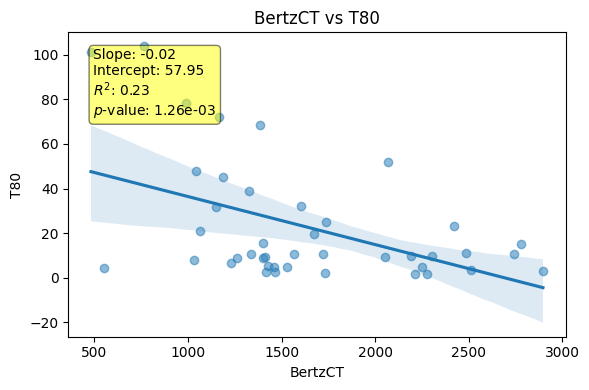

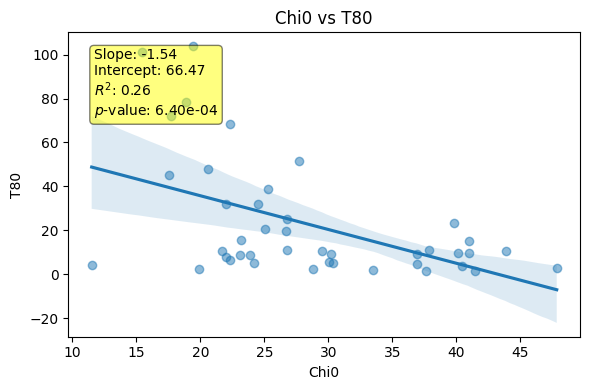

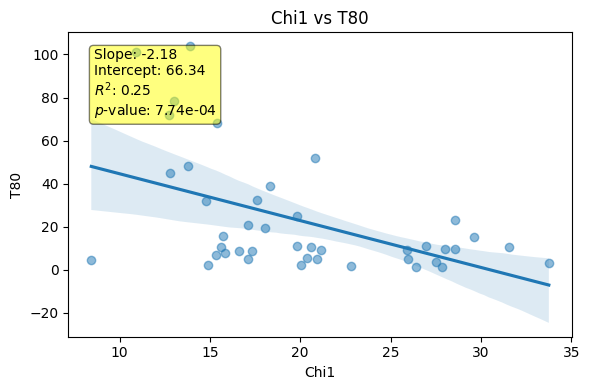

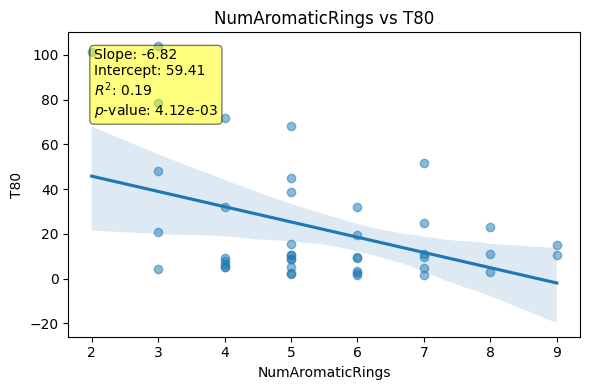

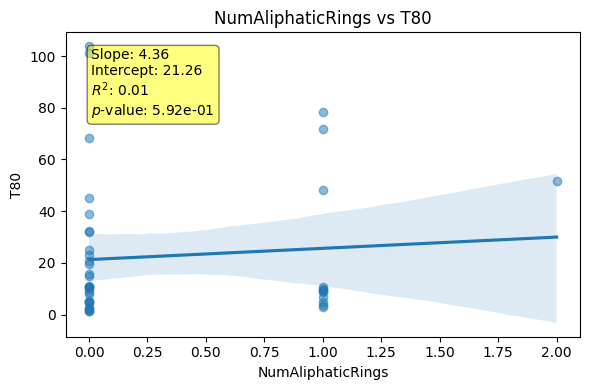

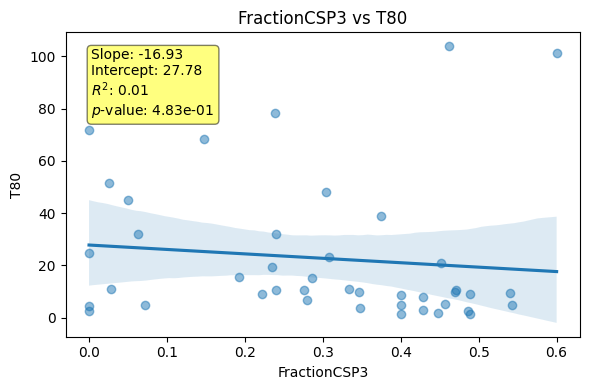

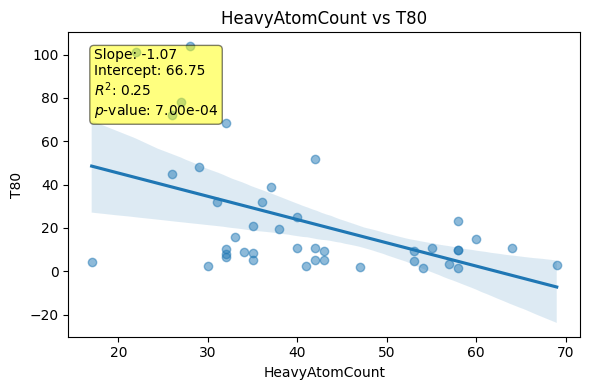

In [18]:
plot_numerical_vs_T80(train, target='T80')

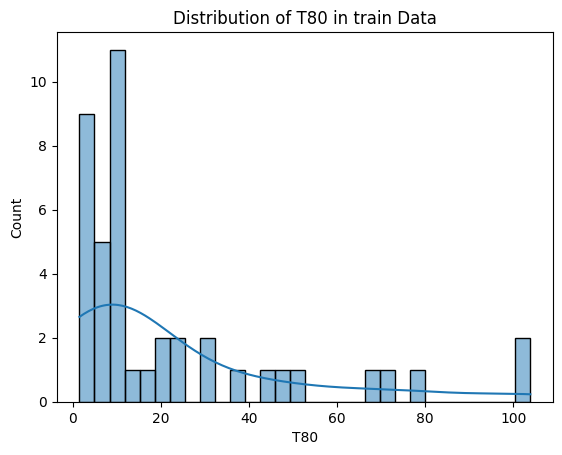

In [19]:
sns.histplot(train['T80'], kde = True, bins=30)
plt.title('Distribution of T80 in train Data')
plt.show()

In [20]:
train['T80'].describe()

count     42.000000
mean      22.710476
std       26.896407
min        1.500000
25%        5.085000
50%       10.485000
75%       30.182500
max      103.860000
Name: T80, dtype: float64

In [21]:
categorical_columns = train.select_dtypes(include=['object', 'category']).columns

# Print categorical columns
print(categorical_columns)

Index(['Smiles', 'mol'], dtype='object')


Only Smiles, and mol - remaining all are numerical columns. 

In [22]:
train.columns

Index(['T80', 'Smiles', 'Mass', 'HAcceptors', 'HDonors', 'LogP', 'Asphericity',
       'Rg', 'TPSA', 'RingCount',
       ...
       'SDOS5.4', 'mol', 'Fsp3', 'BertzCT', 'Chi0', 'Chi1', 'NumAromaticRings',
       'NumAliphaticRings', 'FractionCSP3', 'HeavyAtomCount'],
      dtype='object', length=154)

# Machine Learning Model to predict T80

In [23]:
# Drop Columns:

train.drop(['Smiles', 'mol'], axis =1, inplace =True)
test.drop(['Smiles', 'mol'], axis =1, inplace =True)

In [24]:
target = "T80"
X = train.drop(columns= target)


y = train[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
train.shape

(42, 152)

In [26]:
X_train.shape

(33, 151)

In [27]:


# Define a dictionary of candidate regressors
regressors = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=42),
    "Lasso": Lasso(alpha=0.1, max_iter=10000, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=100, random_state=42)
}

results = {}

print("Evaluating regressors:")

# Iterate through each regressor
for name, reg in regressors.items():
    # Create a pipeline to scale features and fit the regressor
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', reg)
    ])
    
    # Perform 5-fold cross validation on training data (scoring returns negative MSE)
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_rmse = np.mean(np.sqrt(-cv_scores))
    
    # Fit the pipeline on the entire training data and predict on the test set
    pipeline.fit(X_train, y_train)
    test_preds = pipeline.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
    
    results[name] = {"CV_RMSE": cv_rmse, "Test_RMSE": test_rmse}
    print(f"{name}: CV RMSE = {cv_rmse:.4f}, Test RMSE = {test_rmse:.4f}")

# Select the best regressor based on test RMSE
best_regressor_name = min(results, key=lambda x: results[x]["Test_RMSE"])
best_metrics = results[best_regressor_name]
print("\nBest regressor based on test RMSE:")
print(f"{best_regressor_name}: Test RMSE = {best_metrics['Test_RMSE']:.4f}, CV RMSE = {best_metrics['CV_RMSE']:.4f}")


Evaluating regressors:
LinearRegression: CV RMSE = 26.2989, Test RMSE = 35.3739
Ridge: CV RMSE = 26.0240, Test RMSE = 33.7265
Lasso: CV RMSE = 26.7479, Test RMSE = 42.3673
RandomForest: CV RMSE = 19.6425, Test RMSE = 18.1691
GradientBoosting: CV RMSE = 22.6781, Test RMSE = 20.9734
XGBoost: CV RMSE = 22.5010, Test RMSE = 16.8038

Best regressor based on test RMSE:
XGBoost: Test RMSE = 16.8038, CV RMSE = 22.5010


In [28]:
# Define the final XGBoost model with the optimal hyperparameters
final_xgb = xgb.XGBRegressor(
    n_estimators=100,       # Use the best number of trees found
    max_depth=6,            # Use the best depth from your hyperparameter tuning
    learning_rate=0.1,      # Adjust based on your best validation performance
    random_state=42
)

# Re-fit the model on the entire training dataset
final_xgb.fit(X_train, y_train)

# Use the re-fitted model to predict on the test data
preds = final_xgb.predict(X_test)

# Calculate the RMSE
final_rmse = np.sqrt(mean_squared_error(y_test, preds))
print("Final XGBoost RMSE on test set:", final_rmse)

Final XGBoost RMSE on test set: 14.612856995728308


In [29]:
# # # Assuming X and y are your features and numerical target
# # kf = KFold(n_splits=10, shuffle=True, random_state=42)

# # fold_best_iterations = []
# # oof_train_rmse = []
# # oof_val_rmse = []

# # # Loop through folds and use early stopping to capture the optimal boosting rounds
# # for fold, (train_index, val_index) in enumerate(kf.split(X), start=1):
# #     X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
# #     y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]
    
# #     # Define the XGBoost regressor with early stopping enabled
# #     model = XGBRegressor(
# #         n_estimators=1000,
# #         learning_rate=0.03,
# #         max_depth=10,
# #         min_child_weight=4,
# #         colsample_bytree=0.66,
# #         subsample=0.9,
# #         gamma=1.6,
# #         reg_alpha=5.5,
# #         reg_lambda=8,
# #         eval_metric="rmse",
# #         early_stopping_rounds=100,
# #         random_state=42,
# #         tree_method="hist",
# #         verbosity=0
#     )
    
#     # Fit the model using the validation fold for early stopping
#     model.fit(
#         X_train_fold, y_train_fold,
#         eval_set=[(X_val_fold, y_val_fold)],
#         verbose=False
#     )
    
#     # Record the best iteration from early stopping
#     best_iter = model.best_iteration
#     fold_best_iterations.append(best_iter)
    
#     # Compute RMSE on training and validation folds
#     train_rmse = np.sqrt(mean_squared_error(y_train_fold, model.predict(X_train_fold)))
#     val_rmse = np.sqrt(mean_squared_error(y_val_fold, model.predict(X_val_fold)))
#     oof_train_rmse.append(train_rmse)
#     oof_val_rmse.append(val_rmse)
    
#     print(f"Fold {fold}: Best Iteration = {best_iter}, Train RMSE = {train_rmse:.4f}, Val RMSE = {val_rmse:.4f}")

# # Calculate the mean best iteration from all folds
# mean_best_iter = int(np.mean(fold_best_iterations))
# print(f"\nMean Best Iteration from CV: {mean_best_iter}")

# # Optionally, you can also review average RMSEs across folds:
# print(f"Average Train RMSE: {np.mean(oof_train_rmse):.4f}")
# print(f"Average Validation RMSE: {np.mean(oof_val_rmse):.4f}")

# # Retrain final model on the entire dataset using the average best iteration
# final_model = XGBRegressor(
#     n_estimators=mean_best_iter,
#     learning_rate=0.03,
#     max_depth=10,
#     min_child_weight=4,
#     colsample_bytree=0.66,
#     subsample=0.9,
#     gamma=1.6,
#     reg_alpha=5.5,
#     reg_lambda=8,
#     eval_metric="rmse",
#     random_state=42,
#     tree_method="hist",
#     verbosity=0
# )

# final_model.fit(X_train, y_train)



# SHAP Features

In [30]:
test.shape

(9, 151)

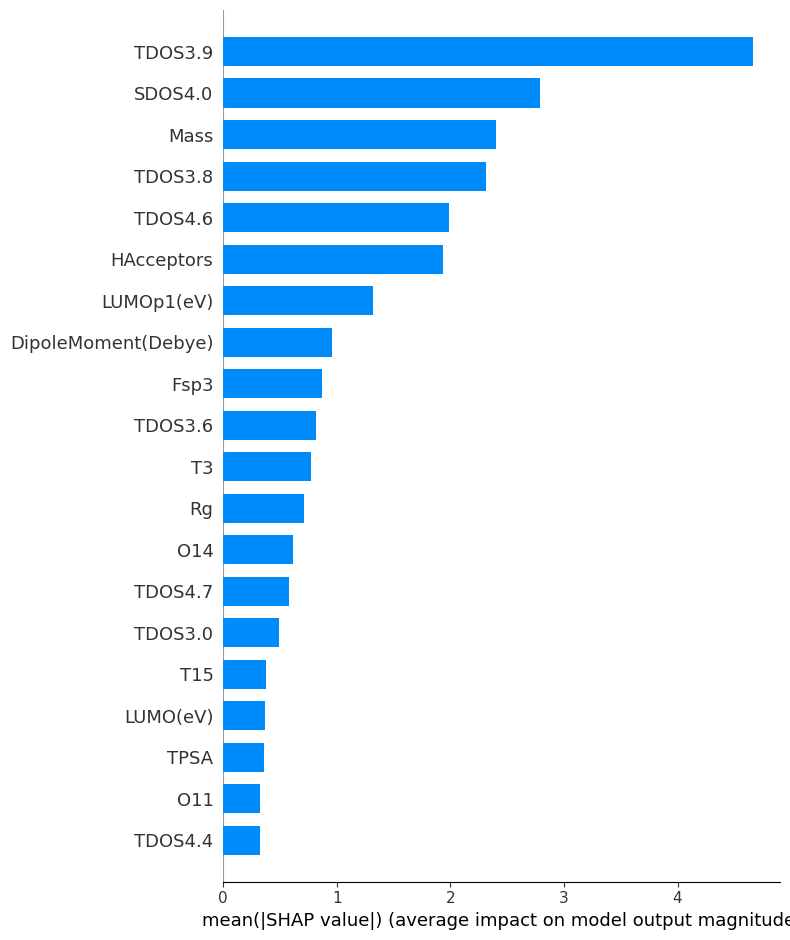

In [31]:
# Initialize the SHAP explainer

explainer = shap.TreeExplainer(final_xgb)
shap_values = explainer(X_test) 

#  Visualize the SHAP summary plot
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [32]:
#test_filtered = test[selected_features]

# Final Prediction

In [33]:
test_pred = final_xgb.predict(test)


submission = pd.DataFrame({'Batch_ID': test.index, 'T80': test_pred})
submission.to_csv('/kaggle/working/submission.csv', index=False)
display(submission)

,Batch_ID,T80
0,Test-01,47.543488
1,Test-02,22.303553
2,Test-03,43.483482
3,Test-04,26.209471
4,Test-05,32.754288
5,Test-06,69.635818
6,Test-07,59.014641
7,Test-08,4.408181
8,Test-09,20.755760
